<a href="https://colab.research.google.com/github/Sandanu87/CRM-CM_CW01_W2054875/blob/main/CRM%26CM_CW1_W2054875.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Task 1 Data Preparation and Feature Engineering**

Installing Yahoo Finance

In [86]:
!pip install yfinance

Importing libraries

In [87]:
import os
import datetime
import numpy as np
import pandas as pd
import requests
import json
import hashlib
import sqlite3
import platform
import sklearn
import scipy
from io import StringIO
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from matplotlib.patches import Patch
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from glob import glob
from scipy.spatial.distance import pdist
from scipy.stats import chi2_contingency, spearmanr, mannwhitneyu
from matplotlib.patches import FancyBboxPatch

In [88]:
start_date = "2021-01-01"
end_date = "2025-01-01"
random_seed = 42

os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("pandas", pd.__version__)
print("numpy", np.__version__)
print("yfinance", yf.__version__)

pandas 2.2.3
numpy 2.4.6
yfinance 0.2.66


In [89]:
def save_fig(name):
    plt.savefig(f"outputs/{name}.png", dpi=150, bbox_inches="tight")

Selecting ticker and Acquiring data

In [90]:
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
headers = {"User-Agent": "Mozilla/5.0"}
response = requests.get(url, headers=headers)
sp500 = pd.read_html(StringIO(response.text))[0]

sp500["Symbol"] = sp500["Symbol"].str.replace(".", "-", regex=False)

retrieval_date = datetime.date.today()
print("Ticker list retrieved on:", retrieval_date)
print("Number of tickers:", len(sp500))

sp500["Retrieved_On"] = retrieval_date
sp500.to_csv("data/sp500_tickers.csv", index=False)

tickers = sp500["Symbol"].tolist()
sp500.head()

Ticker list retrieved on: 2026-11-25
Number of tickers: 503


,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded,Retrieved_On
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902,2026-11-25
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916,2026-11-25
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888,2026-11-25
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888),2026-11-25
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989,2026-11-25


In [91]:
data = yf.download(tickers, start=start_date, end=end_date, auto_adjust=False, actions=True, progress=False)

bench = yf.download("^GSPC", start=start_date, end=end_date, auto_adjust=False, progress=False)
if isinstance(bench.columns, pd.MultiIndex):
    bench.columns = bench.columns.droplevel(1)

print("Share data shape:", data.shape)
print("Benchmark shape:", bench.shape)
print("First date:", data.index.min())
print("Last date:", data.index.max())

ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['HONA', 'VYLR', 'Q', 'FDXF', 'SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Share data shape: (1005, 4014)
Benchmark shape: (1005, 6)
First date: 2021-01-04 00:00:00
Last date: 2024-12-31 00:00:00


In [92]:
data.to_pickle("data/raw_shares.pkl")
bench.to_pickle("data/raw_benchmark.pkl")
data["Adj Close"].to_csv("data/raw_adj_close.csv")
data["Close"].to_csv("data/raw_close.csv")
data["Volume"].to_csv("data/raw_volume.csv")
bench.to_csv("data/raw_benchmark.csv")

Validating and aligning data

In [93]:
print("Duplicate dates in share data:", data.index.duplicated().sum())
print("Duplicate dates in benchmark:", bench.index.duplicated().sum())
data = data[~data.index.duplicated()]
bench = bench[~bench.index.duplicated()]

Duplicate dates in share data: 0
Duplicate dates in benchmark: 0


In [94]:
dates = bench.index
adj_close = data["Adj Close"].reindex(dates)
close = data["Close"].reindex(dates)
volume = data["Volume"].reindex(dates)
splits = data["Stock Splits"].reindex(dates).fillna(0)
dividends = data["Dividends"].reindex(dates).fillna(0)

print("Before cleaning:", adj_close.shape)
print("Benchmark missing values:", bench["Adj Close"].isna().sum())

Before cleaning: (1005, 503)
Benchmark missing values: 0


In [95]:
exclusion_log = []
valid_tickers = []

for t in tickers:
    if t not in adj_close.columns or adj_close[t].isna().all():
        exclusion_log.append([t, "No data downloaded", ""])
        continue

    n_missing = adj_close[t].isna().sum() + close[t].isna().sum() + volume[t].isna().sum()
    if n_missing > 0:
        first_date = adj_close[t].first_valid_index()
        exclusion_log.append([t, "Missing values / unequal history", "first price on " + str(first_date)])
        continue

    if (adj_close[t] <= 0).any() or (close[t] <= 0).any():
        exclusion_log.append([t, "Non-positive price", ""])
        continue

    if (volume[t] <= 0).any():
        exclusion_log.append([t, "Volume error (volume <= 0)", str((volume[t] <= 0).sum()) + " days"])
        continue

    valid_tickers.append(t)

print("Shares requested:", len(tickers))
print("Shares that passed validation:", len(valid_tickers))
print("Shares excluded:", len(exclusion_log))

Shares requested: 503
Shares that passed validation: 486
Shares excluded: 17


In [96]:
adj_close_v = adj_close[valid_tickers]
close_v = close[valid_tickers]
volume_v = volume[valid_tickers]
print("After cleaning:", adj_close_v.shape)
print("Missing values left:", adj_close_v.isna().sum().sum())

After cleaning: (1005, 486)
Missing values left: 0


In [97]:
corp = pd.DataFrame({
    "Splits": (splits[valid_tickers] != 0).sum(),
    "Dividends": (dividends[valid_tickers] > 0).sum(),
    "Max_Daily_Move": adj_close_v.pct_change(fill_method=None).abs().max()
})
print("Shares with at least one split:", (corp["Splits"] > 0).sum())
print("Shares with dividends:", (corp["Dividends"] > 0).sum())
print("Shares with a daily adjusted move above 40% (check manually):")
print(corp[corp["Max_Daily_Move"] > 0.4])

Shares with at least one split: 53
Shares with dividends: 392
Shares with a daily adjusted move above 40% (check manually):
        Splits  Dividends  Max_Daily_Move
Ticker                                   
BE           0          0        0.591867
CVNA         0          0        0.560206
DXCM         1          0        0.406583
GL           0         16        0.531402


Split Check

In [98]:
split_rows = []
for t in valid_tickers:
    s = splits[t]
    for d in s.index[s != 0]:
        i = close.index.get_loc(d)
        if i < 1 or i + 1 >= len(close):
            continue
        ratio = float(s[d])
        adj_move = adj_close[t].iloc[i] / adj_close[t].iloc[i - 1] - 1
        close_move = close[t].iloc[i] / close[t].iloc[i - 1] - 1
        vol_before = volume[t].iloc[max(0, i - 20):i].median()
        vol_after = volume[t].iloc[i:i + 20].median()
        vol_change = vol_after / vol_before
        big_split = abs(np.log(ratio)) > 0.3
        close_unadjusted = big_split and abs(np.log((1 + close_move) / (1 / ratio))) < 0.15
        volume_unadjusted = big_split and abs(np.log(vol_change / ratio)) < 0.25
        split_rows.append([t, d.date(), ratio, round(adj_move, 4), round(close_move, 4), round(vol_change, 2),
                           close_unadjusted, volume_unadjusted])

split_check = pd.DataFrame(split_rows, columns=["Ticker", "Date", "Split_ratio", "Adj_Close_move", "Close_move",
                                                "Volume_after_vs_before", "Close_looks_unadjusted", "Volume_looks_unadjusted"])
split_check["Flagged"] = split_check["Close_looks_unadjusted"] | split_check["Volume_looks_unadjusted"]

print("Recorded split events (valid shares):", len(split_check))
print("Shares with at least one split:", split_check["Ticker"].nunique())
print("Events passing the continuity check:", int((~split_check["Flagged"]).sum()))
print("Events flagged for manual review:", int(split_check["Flagged"].sum()))
print(split_check[split_check["Flagged"]].to_string(index=False) if split_check["Flagged"].any() else "No flagged split events.")
split_check.to_csv("outputs/split_check.csv", index=False)

Recorded split events (valid shares): 61
Shares with at least one split: 53
Events passing the continuity check: 60
Events flagged for manual review: 1
Ticker       Date  Split_ratio  Adj_Close_move  Close_move  Volume_after_vs_before  Close_looks_unadjusted  Volume_looks_unadjusted  Flagged
   RJF 2021-09-22          1.5          0.0119      0.0119                    1.24                   False                     True     True


In [99]:
t = "RJF"
d = pd.Timestamp("2021-09-22")
i = volume.index.get_loc(d)
rjf_change = volume[t].iloc[i:i+60].median() / volume[t].iloc[max(0, i-60):i].median()
mkt_change = (volume[valid_tickers].iloc[i:i+60].median() / volume[valid_tickers].iloc[max(0, i-60):i].median()).median()
print("RJF volume change (60 sessions after / before):", round(rjf_change, 2))
print("Median change across all valid shares, same dates:", round(mkt_change, 2))

obs_date = adj_close_v.index[-1]
print("Observation date:", obs_date.date(), obs_date.day_name())
v = volume_v[t]
avg20 = v.shift(1).rolling(20).mean()
high_volume = v > 2 * avg20
event_dates = v.index[high_volume]
recency = (obs_date - event_dates[-1]).days if len(event_dates) > 0 else np.nan

last_event = obs_date - pd.Timedelta(days=int(recency))
print("RJF latest high-volume event:", last_event.date(), "| split date:", d.date())

RJF volume change (60 sessions after / before): 1.16
Median change across all valid shares, same dates: 1.07
Observation date: 2024-12-31 Tuesday
RJF latest high-volume event: 2024-12-20 | split date: 2021-09-22


Weekly return & beta

In [100]:
def calculate_weekly_returns(weekly_prices):
    """Weekly return = price this week / price last week - 1"""
    if len(weekly_prices) < 3:
        raise ValueError("Not enough weeks")
    returns = weekly_prices.pct_change(fill_method=None)
    return returns.iloc[1:]


def calculate_weekly_beta(share_returns, bench_returns, min_weeks=52):
    """Beta = covariance(share, benchmark) / variance(benchmark)"""
    both = pd.concat([share_returns, bench_returns], axis=1)
    both = both.replace([np.inf, -np.inf], np.nan).dropna()
    if len(both) < min_weeks:
        raise ValueError("Not enough aligned weeks")
    var_bench = both.iloc[:, 1].var()
    if var_bench <= 0:
        raise ValueError("Benchmark variance must be above 0")
    beta = both.iloc[:, 0].cov(both.iloc[:, 1]) / var_bench
    return beta, len(both)

Mean weekly return

In [101]:
weekly_adj = adj_close_v.resample("W-FRI").last()
weekly_bench = bench["Adj Close"].resample("W-FRI").last()

print("First week label:", weekly_adj.index[0].date())
print("Last week label:", weekly_adj.index[-1].date())

First week label: 2021-01-08
Last week label: 2025-01-03


In [102]:
weekly_adj = weekly_adj.iloc[:-1]
weekly_bench = weekly_bench.iloc[:-1]

print("Weekly price observations:", len(weekly_adj))
print("Same week labels for shares and benchmark:", weekly_adj.index.equals(weekly_bench.index))
print("Missing weekly prices:", weekly_adj.isna().sum().sum())

Weekly price observations: 208
Same week labels for shares and benchmark: True
Missing weekly prices: 0


In [103]:
weekly_returns = calculate_weekly_returns(weekly_adj)
bench_returns = calculate_weekly_returns(weekly_bench)
print("Weekly return observations:", len(weekly_returns))

Weekly return observations: 207


Weekly Beta

In [104]:
rr_list = []
for t in valid_tickers:
    beta, n_weeks = calculate_weekly_beta(weekly_returns[t], bench_returns)
    mean_return = weekly_returns[t].mean()
    rr_list.append([t, mean_return, beta, n_weeks])

risk_return = pd.DataFrame(rr_list, columns=["Ticker", "Mean_Weekly_Return", "Weekly_Beta", "N_Weeks"])
print(risk_return.describe().round(4))

       Mean_Weekly_Return  Weekly_Beta  N_Weeks
count            486.0000     486.0000    486.0
mean               0.0029       0.9737    207.0
std                0.0027       0.4073      0.0
min               -0.0045       0.0555    207.0
25%                0.0012       0.6666    207.0
50%                0.0026       0.9506    207.0
75%                0.0042       1.1795    207.0
max                0.0178       3.7786    207.0


In [105]:
t = valid_tickers[0]
slope = np.polyfit(bench_returns.values, weekly_returns[t].values, 1)[0]
print("Check for", t, "- beta:", round(risk_return.loc[0, "Weekly_Beta"], 6), "- regression slope:", round(slope, 6))

Check for MMM - beta: 0.869079 - regression slope: 0.869079


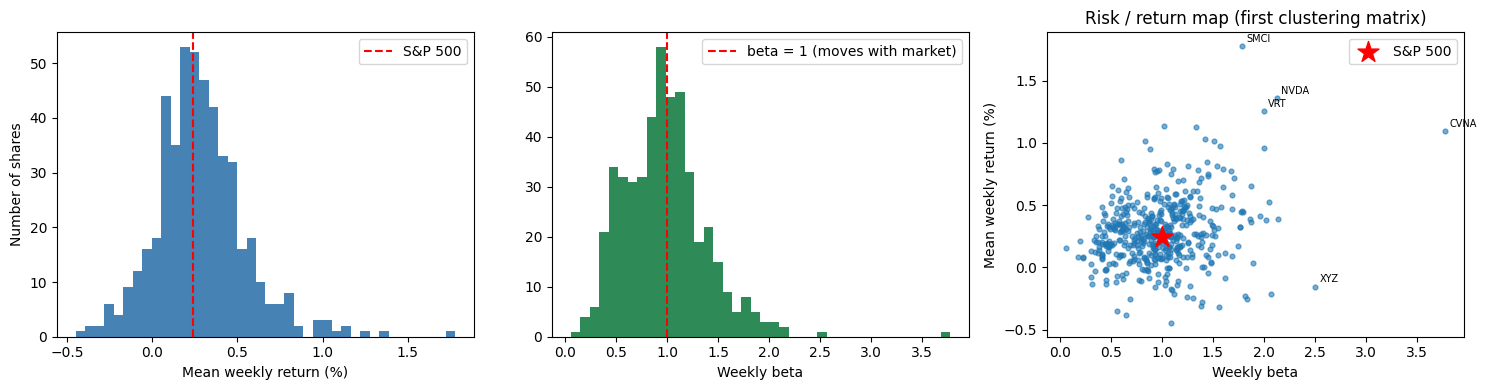

In [106]:
bench_mean = bench_returns.mean() * 100
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(risk_return["Mean_Weekly_Return"] * 100, bins=40, color="steelblue")
axes[0].axvline(bench_mean, color="red", ls="--", label="S&P 500")
axes[0].set_xlabel("Mean weekly return (%)"); axes[0].set_ylabel("Number of shares"); axes[0].legend()

axes[1].hist(risk_return["Weekly_Beta"], bins=40, color="seagreen")
axes[1].axvline(1, color="red", ls="--", label="beta = 1 (moves with market)")
axes[1].set_xlabel("Weekly beta"); axes[1].legend()

axes[2].scatter(risk_return["Weekly_Beta"], risk_return["Mean_Weekly_Return"] * 100, s=12, alpha=0.6)
axes[2].scatter([1], [bench_mean], marker="*", s=250, color="red", label="S&P 500", zorder=5)
for _, r in pd.concat([risk_return.nlargest(3, "Mean_Weekly_Return"), risk_return.nlargest(2, "Weekly_Beta")]).drop_duplicates("Ticker").iterrows():
    axes[2].annotate(r["Ticker"], (r["Weekly_Beta"], r["Mean_Weekly_Return"] * 100), fontsize=7, xytext=(3, 3), textcoords="offset points")
axes[2].set_xlabel("Weekly beta"); axes[2].set_ylabel("Mean weekly return (%)"); axes[2].legend()
axes[2].set_title("Risk / return map (first clustering matrix)")
plt.tight_layout()
save_fig("g3_return_beta_distributions")
plt.show()

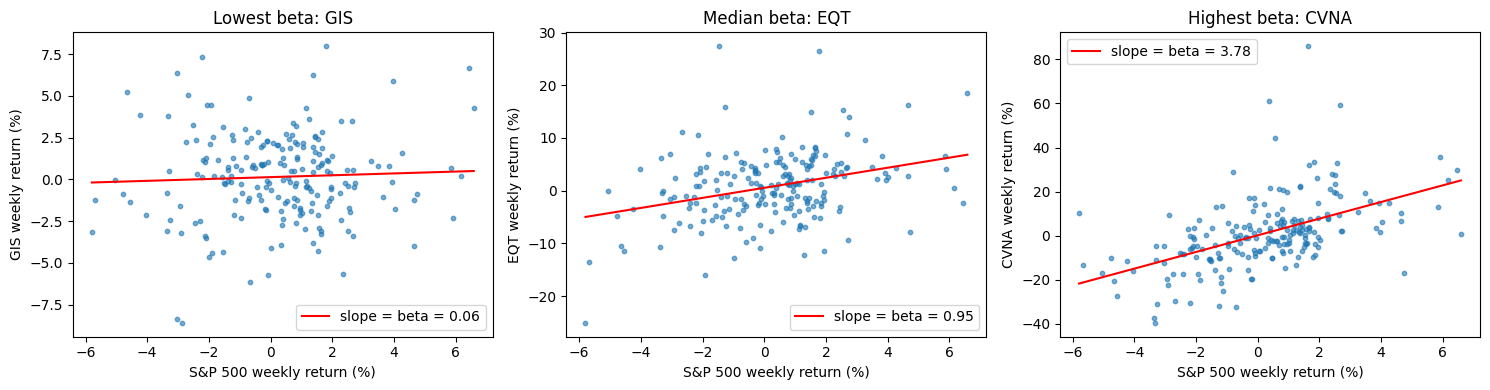

In [107]:
sorted_beta = risk_return.sort_values("Weekly_Beta").reset_index(drop=True)
picks = [("Lowest beta", sorted_beta.iloc[0]), ("Median beta", sorted_beta.iloc[len(sorted_beta) // 2]),
         ("Highest beta", sorted_beta.iloc[-1])]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (title, row) in zip(axes, picks):
    t = row["Ticker"]
    x, y = bench_returns * 100, weekly_returns[t] * 100
    slope, intercept = np.polyfit(x, y, 1)
    ax.scatter(x, y, s=10, alpha=0.6)
    xs = np.linspace(x.min(), x.max(), 50)
    ax.plot(xs, slope * xs + intercept, color="red", label=f"slope = beta = {slope:.2f}")
    ax.set_title(f"{title}: {t}"); ax.set_xlabel("S&P 500 weekly return (%)"); ax.set_ylabel(f"{t} weekly return (%)")
    ax.legend()
plt.tight_layout()
save_fig("g4_beta_examples")
plt.show()

Adapted RFM Calculations

In [108]:
obs_date = adj_close_v.index[-1]
print("Observation date:", obs_date.date(), obs_date.day_name())

rfm_list = []
for t in valid_tickers:
    v = volume_v[t]
    c = close_v[t]

    avg20 = v.shift(1).rolling(20).mean()
    high_volume = v > 2 * avg20

    event_dates = v.index[high_volume]
    if len(event_dates) > 0:
        recency = (obs_date - event_dates[-1]).days
    else:
        recency = np.nan

    last60 = v.index[-60:]

    frequency = high_volume.loc[last60].sum()

    monetary = (c.loc[last60] * v.loc[last60]).sum()

    rfm_list.append([t, recency, frequency, monetary])

rfm = pd.DataFrame(rfm_list, columns=["Ticker", "R", "F", "M"])

print(rfm.describe().round(1))
print("Shares with no high volume day (R = NaN):", rfm["R"].isna().sum())
print("Shares with an event on the observation date (R = 0):", (rfm["R"] == 0).sum())
print("Maximum F (must be 60 or less):", rfm["F"].max())

Observation date: 2024-12-31 Tuesday
           R      F             M
count  486.0  486.0  4.860000e+02
mean    20.4    3.0  3.940419e+10
std     21.3    1.3  1.291388e+11
min      4.0    0.0  1.297483e+09
25%     11.0    2.0  1.019517e+10
50%     11.0    3.0  1.668382e+10
75%     14.8    4.0  3.227689e+10
max    222.0    8.0  1.847697e+12
Shares with no high volume day (R = NaN): 0
Shares with an event on the observation date (R = 0): 0
Maximum F (must be 60 or less): 8


Most common latest-event date: 2024-12-20 for 353 of 486 shares (73%)


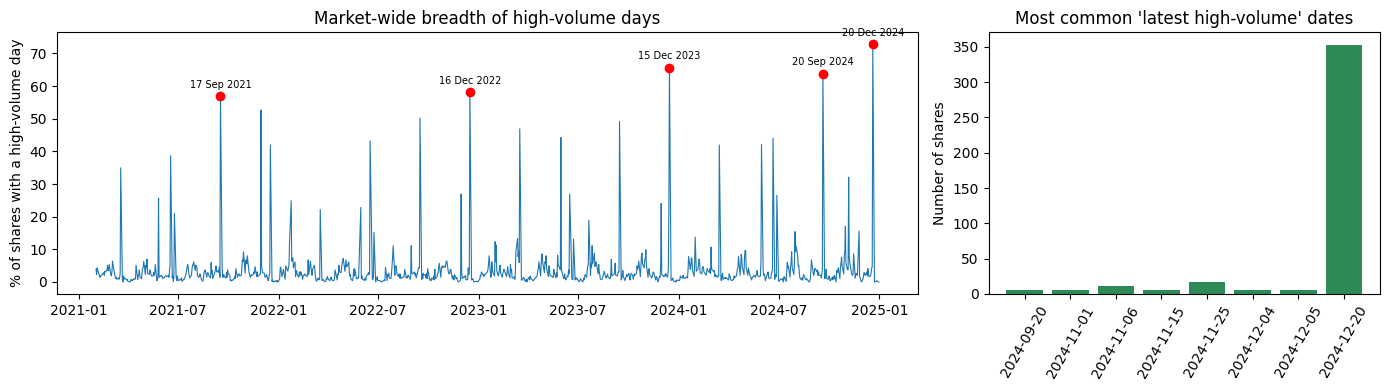

In [109]:
avg20_all = volume_v.shift(1).rolling(20).mean()
flags_all = volume_v > 2 * avg20_all
breadth = (flags_all.mean(axis=1) * 100).iloc[20:]
top5 = breadth.nlargest(5)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].plot(breadth.index, breadth.values, lw=0.8)
axes[0].scatter(top5.index, top5.values, color="red", zorder=5)
for d, v in top5.items():
    axes[0].annotate(d.strftime("%d %b %Y"), (d, v), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=7)
axes[0].set_ylabel("% of shares with a high-volume day"); axes[0].set_title("Market-wide breadth of high-volume days")

latest_event = obs_date - pd.to_timedelta(rfm["R"], unit="D")
common = latest_event.value_counts().head(8).sort_index()
axes[1].bar(common.index.strftime("%Y-%m-%d"), common.values, color="seagreen")
axes[1].tick_params(axis="x", rotation=60)
axes[1].set_ylabel("Number of shares"); axes[1].set_title("Most common 'latest high-volume' dates")
plt.tight_layout()
save_fig("g6_market_wide_breadth")
top_date = latest_event.value_counts().index[0]
print(f"Most common latest-event date: {top_date.date()} for {latest_event.value_counts().iloc[0]} of {len(rfm)} shares "
      f"({latest_event.value_counts().iloc[0] / len(rfm):.0%})")
plt.show()

In [110]:
prev20_mean_all = volume_v[valid_tickers].shift(1).rolling(20).mean()
testable_mask = prev20_mean_all.notna()
hv_mask = (volume_v[valid_tickers] > 2 * prev20_mean_all) & testable_mask

total_testable_days = int(testable_mask.sum().sum())
total_hv_events = int(hv_mask.sum().sum())
hv_pct = (total_hv_events / total_testable_days) * 100

common_r = int(rfm["R"].mode().iloc[0])
common_r_count = int((rfm["R"] == common_r).sum())
common_r_pct = (common_r_count / len(rfm)) * 100
f_zero_count = int((rfm["F"] == 0).sum())

top_m = rfm.nlargest(3, "M")[["Ticker", "R", "F", "M"]].copy()
top_m["M_Billions"] = (top_m["M"] / 1e9).round(2)

print(f"Qualifying high-volume share-days: {total_hv_events:,} / {total_testable_days:,} ({hv_pct:.2f}%)")
print(f"Recency median: {rfm['R'].median():.0f} calendar days | Most common R: {common_r} days ({common_r_count} shares, {common_r_pct:.1f}%)")
print(f"Frequency mean: {rfm['F'].mean():.2f} | Range: {int(rfm['F'].min())} to {int(rfm['F'].max())} | Shares with F = 0: {f_zero_count}")
print(f"Monetary median: ${rfm['M'].median()/1e9:.2f}B | Mean: ${rfm['M'].mean()/1e9:.2f}B")
print("\nTop 3 shares by Monetary (60-session traded value):")
print(top_m[["Ticker", "R", "F", "M_Billions"]].to_string(index=False))

Qualifying high-volume share-days: 18,280 / 478,710 (3.82%)
Recency median: 11 calendar days | Most common R: 11 days (353 shares, 72.6%)
Frequency mean: 2.99 | Range: 0 to 8 | Shares with F = 0: 10
Monetary median: $16.68B | Mean: $39.40B

Top 3 shares by Monetary (60-session traded value):
Ticker   R  F  M_Billions
  TSLA  50  5     1847.70
  NVDA 222  0     1825.34
  AAPL  11  2      623.30


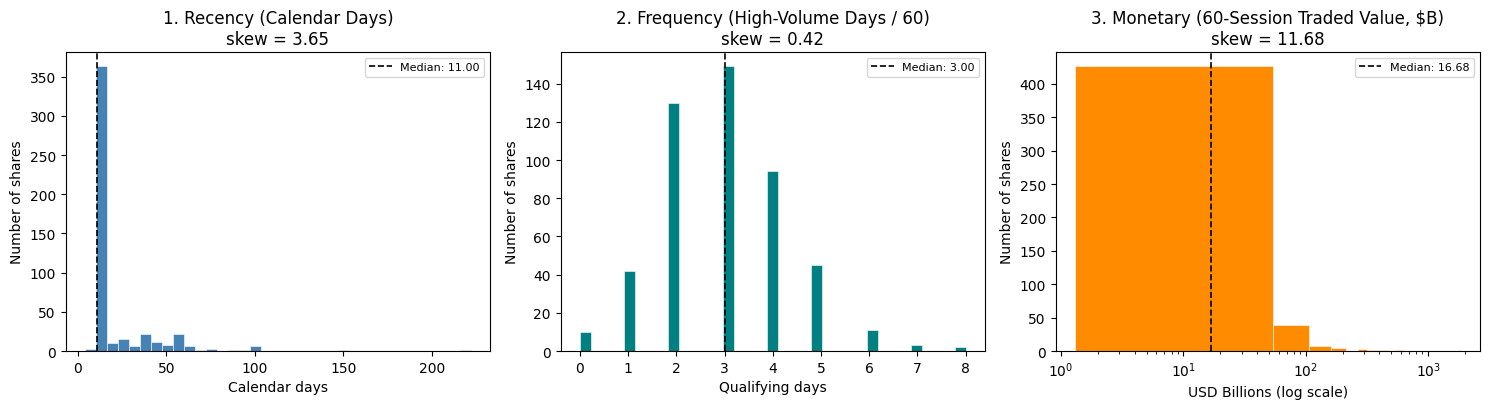

In [111]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

rfm_panels = [
    ("R", "1. Recency (Calendar Days)", rfm["R"], "steelblue", False),
    ("F", "2. Frequency (High-Volume Days / 60)", rfm["F"], "teal", False),
    ("M", "3. Monetary (60-Session Traded Value, $B)", rfm["M"] / 1e9, "darkorange", True),
]

for ax, (_, title, vals, colour, log_scale) in zip(axes, rfm_panels):
    ax.hist(vals.dropna(), bins=35, color=colour, edgecolor="white", linewidth=0.4)
    if log_scale:
        ax.set_xscale("log")
    med_val = vals.median()
    ax.axvline(med_val, color="black", linestyle="--", linewidth=1.2, label=f"Median: {med_val:,.2f}")
    ax.set_title(f"{title}\nskew = {vals.skew():.2f}")
    ax.set_xlabel("Calendar days" if _ == "R" else ("Qualifying days" if _ == "F" else "USD Billions (log scale)"))
    ax.set_ylabel("Number of shares")
    ax.legend(fontsize=8)

plt.tight_layout()
save_fig("g_rfm_only_distributions")
plt.show()

Metric interpretation and supporting evidence

In [112]:
example = "AAPL" if "AAPL" in valid_tickers else valid_tickers[0]
v = volume_v[example]
avg20 = v.shift(1).rolling(20).mean()

table = pd.DataFrame({
    "Close": close_v[example],
    "Volume": v,
    "Avg_prev_20": avg20,
    "Threshold": 2 * avg20,
    "High_Volume": v > 2 * avg20,
    "Close_x_Volume": close_v[example] * v
})
print("Example:", example)
print(table.tail(10).round(2).to_string())

Example: AAPL
             Close     Volume  Avg_prev_20    Threshold  High_Volume  Close_x_Volume
Date                                                                                
2024-12-17  253.48   51356400   42354720.0   84709440.0        False    1.301782e+10
2024-12-18  248.05   56774100   42690855.0   85381710.0        False    1.408282e+10
2024-12-19  249.79   60882300   43718970.0   87437940.0        False    1.520779e+10
2024-12-20  254.49  147495300   45004605.0   90009210.0         True    3.753608e+10
2024-12-23  255.27   40858800   50273955.0  100547910.0        False    1.043003e+10
2024-12-24  258.20   23234700   50408480.0  100816960.0        False    5.999200e+09
2024-12-26  259.02   27237100   47062575.0   94125150.0        False    7.054953e+09
2024-12-27  255.59   42355300   46125120.0   92250240.0        False    1.082559e+10
2024-12-30  252.20   35557500   46567965.0   93135930.0        False    8.967601e+09
2024-12-31  250.42   39480700   46921770.0   938435

In [113]:
row = rfm[rfm["Ticker"] == example].iloc[0]
latest_event = table.index[table["High_Volume"]][-1]
print("Latest high volume day:", latest_event.date())
print("R =", obs_date.date(), "-", latest_event.date(), "=", row["R"], "days")
print("F =", row["F"], "high volume days in the last 60 sessions")
print("M = $", round(row["M"]))

Latest high volume day: 2024-12-20
R = 2024-12-31 - 2024-12-20 = 11 days
F = 2 high volume days in the last 60 sessions
M = $ 623303377707


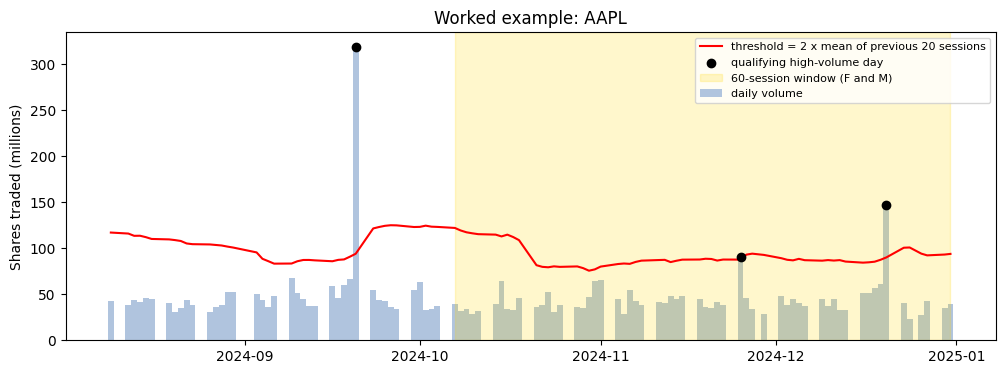

In [114]:
recent = table.tail(100)
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(recent.index, recent["Volume"] / 1e6, width=1.0, color="lightsteelblue", label="daily volume")
ax.plot(recent.index, recent["Threshold"] / 1e6, color="red", label="threshold = 2 x mean of previous 20 sessions")
events = recent[recent["High_Volume"]]
ax.scatter(events.index, events["Volume"] / 1e6, color="black", zorder=5, label="qualifying high-volume day")
ax.axvspan(table.index[-60], table.index[-1], color="gold", alpha=0.2, label="60-session window (F and M)")
ax.set_ylabel("Shares traded (millions)")
ax.set_title(f"Worked example: {example}")
ax.legend(fontsize=8)
save_fig("g7_worked_example")
plt.show()

In [115]:
count = 0
total = 0
for i in range(len(v) - 60, len(v)):
    average = v.iloc[i - 20:i].mean()
    if v.iloc[i] > 2 * average:
        count = count + 1
    total = total + close_v[example].iloc[i] * v.iloc[i]
print("Manual check - F:", count, "M:", round(total))

Manual check - F: 2 M: 623303377707


Feature summary

In [116]:
for t in rfm.loc[rfm["R"].isna(), "Ticker"]:
    exclusion_log.append([t, "No high volume day (R missing)", "excluded from clustering, R not set to 0"])

features = sp500[["Symbol", "Security", "GICS Sector"]].rename(columns={"Symbol": "Ticker"})
features = features.merge(risk_return, on="Ticker").merge(rfm, on="Ticker")
print("Before removing missing values:", features.shape)

Before removing missing values: (486, 9)


In [117]:
features = features.dropna().reset_index(drop=True)
print("Common valid share set:", features.shape)

Common valid share set: (486, 9)


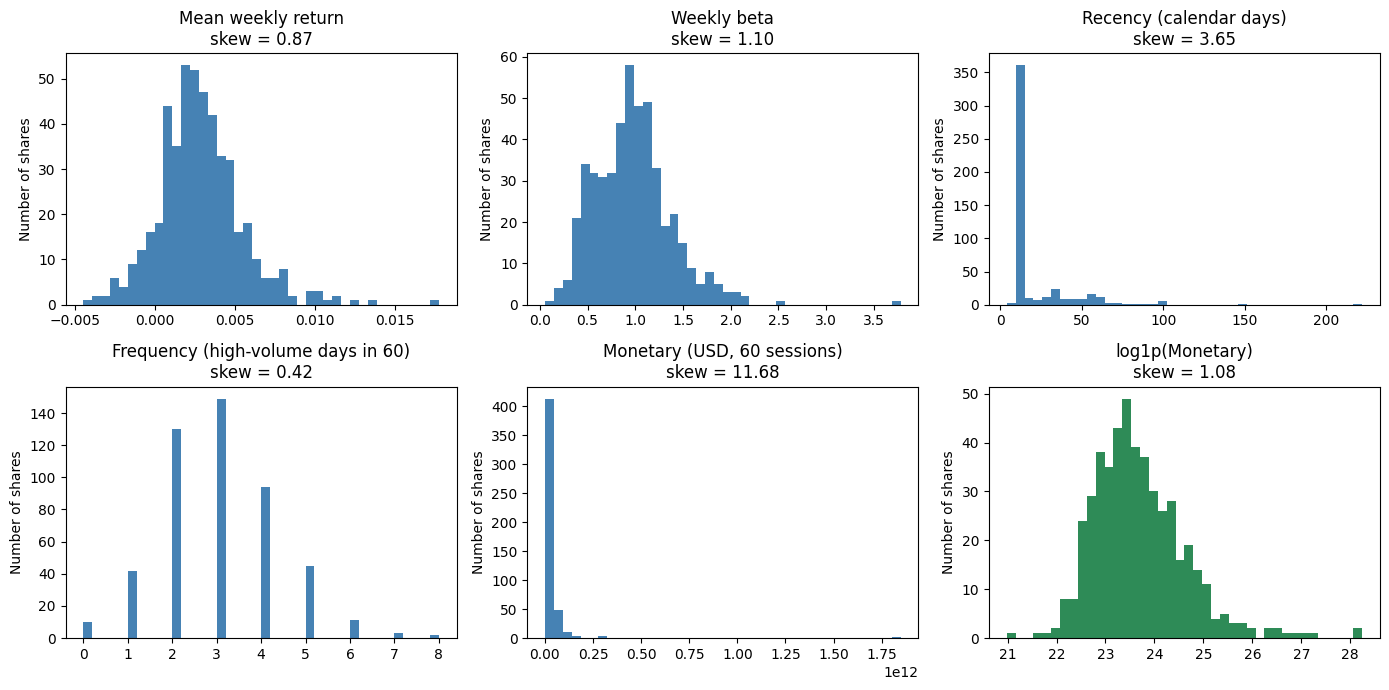

In [118]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
items = [("Mean_Weekly_Return", "Mean weekly return", features["Mean_Weekly_Return"], "steelblue"),
         ("Weekly_Beta", "Weekly beta", features["Weekly_Beta"], "steelblue"),
         ("R", "Recency (calendar days)", features["R"], "steelblue"),
         ("F", "Frequency (high-volume days in 60)", features["F"], "steelblue"),
         ("M", "Monetary (USD, 60 sessions)", features["M"], "steelblue"),
         ("logM", "log1p(Monetary)", np.log1p(features["M"]), "seagreen")]
for ax, (_, title, vals, colour) in zip(axes.ravel(), items):
    ax.hist(vals, bins=40, color=colour)
    ax.set_title(f"{title}\nskew = {vals.skew():.2f}"); ax.set_ylabel("Number of shares")
plt.tight_layout()
save_fig("g8_feature_distributions")
plt.show()

Inclusion/ Exclusion logs

In [119]:
exclusion_df = pd.DataFrame(exclusion_log, columns=["Ticker", "Reason", "Detail"])
print(exclusion_df["Reason"].value_counts())

exclusion_df.to_csv("outputs/exclusion_log.csv", index=False)
features.to_csv("outputs/feature_table.csv", index=False)
print(features[["Mean_Weekly_Return", "Weekly_Beta", "R", "F", "M"]].describe().round(4))

Reason
Missing values / unequal history    10
No data downloaded                   5
Volume error (volume <= 0)           2
Name: count, dtype: int64
       Mean_Weekly_Return  Weekly_Beta         R         F             M
count            486.0000     486.0000  486.0000  486.0000  4.860000e+02
mean               0.0029       0.9737   20.4074    2.9897  3.940419e+10
std                0.0027       0.4073   21.3424    1.3308  1.291388e+11
min               -0.0045       0.0555    4.0000    0.0000  1.297483e+09
25%                0.0012       0.6666   11.0000    2.0000  1.019517e+10
50%                0.0026       0.9506   11.0000    3.0000  1.668382e+10
75%                0.0042       1.1795   14.7500    4.0000  3.227689e+10
max                0.0178       3.7786  222.0000    8.0000  1.847697e+12


In [120]:
print("Exclusion Log")
display(exclusion_df)
print()
print("Feature Table")
display(features.head(15))

Exclusion Log


,Ticker,Reason,Detail
0,APP,Missing values / unequal history,first price on 2021-04-15 00:00:00
1,COIN,Missing values / unequal history,first price on 2021-04-14 00:00:00
2,CEG,Missing values / unequal history,first price on 2022-01-19 00:00:00
3,EXE,Missing values / unequal history,first price on 2021-02-10 00:00:00
4,FDXF,No data downloaded,
5,FERG,Volume error (volume <= 0),27 days
6,GEHC,Missing values / unequal history,first price on 2022-12-15 00:00:00
7,GEV,Missing values / unequal history,first price on 2024-03-27 00:00:00
8,HONA,No data downloaded,
9,Q,No data downloaded,



Feature Table


,Ticker,Security,GICS Sector,Mean_Weekly_Return,Weekly_Beta,N_Weeks,R,F,M
0,MMM,3M,Industrials,0.001142,0.869079,207,11,4,2.599146e+10
1,AOS,A. O. Smith,Industrials,0.001991,1.042805,207,11,2,4.748980e+09
2,ABT,Abbott Laboratories,Health Care,0.000971,0.583543,207,11,1,3.523027e+10
3,ABBV,AbbVie,Health Care,0.003749,0.425366,207,11,3,6.837054e+10
4,ACN,Accenture,Information Technology,0.002376,1.143300,207,11,2,5.199430e+10
5,ADBE,Adobe Inc.,Information Technology,0.000990,1.553525,207,18,3,1.030403e+11
6,AMD,Advanced Micro Devices,Information Technology,0.003624,1.877622,207,18,4,3.131659e+11
7,AES,AES Corporation,Utilities,-0.001420,1.143913,207,54,3,1.119578e+10
8,AFL,Aflac,Financials,0.005004,0.707197,207,11,2,1.328456e+10
9,A,Agilent Technologies,Health Care,0.001121,1.074724,207,11,2,1.400180e+10


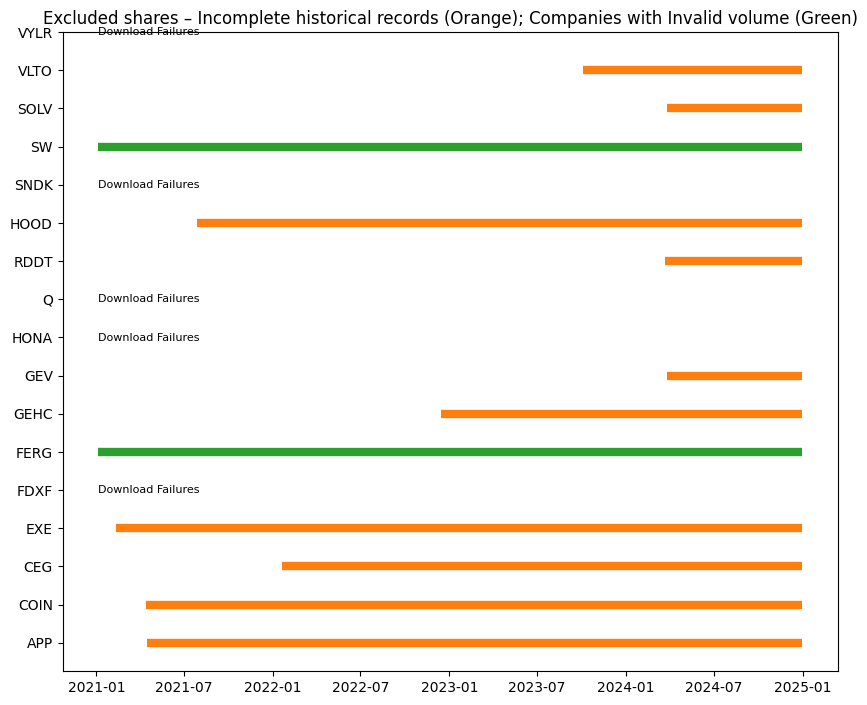

In [121]:
excl = exclusion_df[~exclusion_df["Reason"].str.startswith("No high")].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 0.4 * len(excl) + 1.5))
for i, row in excl.iterrows():
    t = row["Ticker"]
    if row["Reason"] == "No data downloaded":
        ax.text(dates[0], i, "Download Failures", va="center", color="black", fontsize=8)
    else:
        start = adj_close[t].first_valid_index() if t in adj_close.columns else None
        colour = "tab:green" if "Volume" in row["Reason"] else "tab:orange"
        if start is not None:
            ax.hlines(i, start, dates[-1], colors=colour, linewidth=6)
ax.set_yticks(range(len(excl)))
ax.set_yticklabels(excl["Ticker"])
ax.set_title("Excluded shares – Incomplete historical records (Orange); Companies with Invalid volume (Green)")
save_fig("g2_exclusion_timeline")
plt.show()

Final count from the funnel: 486 | shares in your feature table: 486


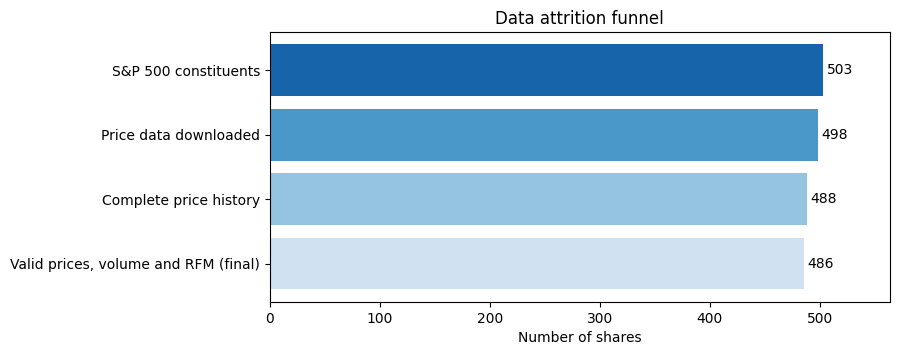

In [122]:
reasons = exclusion_df["Reason"].value_counts()
n_total = len(tickers)
n_nodata = reasons.get("No data downloaded", 0)
n_hist = reasons.get("Missing values / unequal history", 0)
n_other = (reasons.get("Volume error (volume <= 0)", 0) + reasons.get("Non-positive price", 0)
           + reasons.get("No high volume day (R missing)", 0))

steps = ["S&P 500 constituents", "Price data downloaded", "Complete price history", "Valid prices, volume and RFM (final)"]
counts = [n_total, n_total - n_nodata, n_total - n_nodata - n_hist, n_total - n_nodata - n_hist - n_other]
print("Final count from the funnel:", counts[-1], "| shares in your feature table:", len(features))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(steps[::-1], counts[::-1], color=sns.color_palette("Blues", 4))
for i, v in enumerate(counts[::-1]):
    ax.text(v + 3, i, str(v), va="center")
ax.set_xlim(0, n_total * 1.12)
ax.set_xlabel("Number of shares")
ax.set_title("Data attrition funnel")
save_fig("g1_attrition_funnel")
plt.show()

# **Task 2 Stock Segmentation and Sensitivity Analysis**

**Feature preparation**

In [123]:
X_rr_raw = features[["Mean_Weekly_Return", "Weekly_Beta"]].copy()

X_rfm_raw = features[["R", "F"]].copy()
X_rfm_raw["log1p_M"] = np.log1p(features["M"])

print("Skew of M before log1p:", round(features["M"].skew(), 2))
print("Skew of M after log1p:", round(X_rfm_raw["log1p_M"].skew(), 2))
print("Skew of R:", round(features["R"].skew(), 2), "| F:", round(features["F"].skew(), 2))
print("Skew of return:", round(features["Mean_Weekly_Return"].skew(), 2), "| beta:", round(features["Weekly_Beta"].skew(), 2))


Skew of M before log1p: 11.68
Skew of M after log1p: 1.08
Skew of R: 3.65 | F: 0.42
Skew of return: 0.87 | beta: 1.1


Mean_Weekly_Return outliers (|z| > 3): 6
Weekly_Beta outliers (|z| > 3): 2
R outliers (|z| > 3): 11
F outliers (|z| > 3): 5
log1p_M outliers (|z| > 3): 7


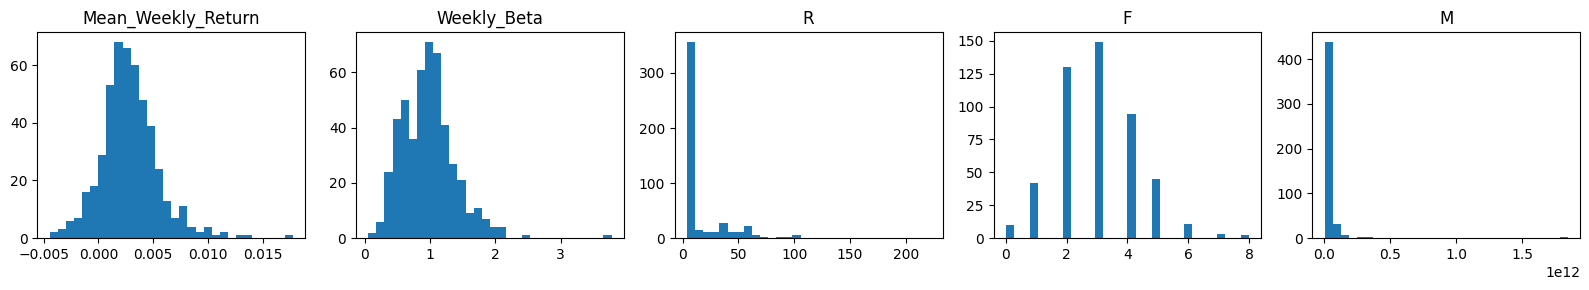

In [124]:
for col in ["Mean_Weekly_Return", "Weekly_Beta"]:
    z = (X_rr_raw[col] - X_rr_raw[col].mean()) / X_rr_raw[col].std()
    print(col, "outliers (|z| > 3):", (z.abs() > 3).sum())
for col in ["R", "F", "log1p_M"]:
    z = (X_rfm_raw[col] - X_rfm_raw[col].mean()) / X_rfm_raw[col].std()
    print(col, "outliers (|z| > 3):", (z.abs() > 3).sum())

fig, axes = plt.subplots(1, 5, figsize=(16, 3))
for ax, col in zip(axes, ["Mean_Weekly_Return", "Weekly_Beta", "R", "F", "M"]):
    ax.hist(features[col], bins=30)
    ax.set_title(col)
plt.tight_layout()
plt.savefig("outputs/fig_distributions.png", dpi=150)
plt.show()

In [125]:
scaler1 = StandardScaler()
X_rr = pd.DataFrame(scaler1.fit_transform(X_rr_raw), columns=X_rr_raw.columns)

scaler2 = StandardScaler()
X_rfm = pd.DataFrame(scaler2.fit_transform(X_rfm_raw), columns=X_rfm_raw.columns)

print("Number of shares in both matrices:", X_rr.shape[0], X_rfm.shape[0])
print(X_rr.describe().round(2))

Number of shares in both matrices: 486 486
       Mean_Weekly_Return  Weekly_Beta
count              486.00       486.00
mean                -0.00         0.00
std                  1.00         1.00
min                 -2.77        -2.26
25%                 -0.63        -0.75
50%                 -0.09        -0.06
75%                  0.51         0.51
max                  5.63         6.89


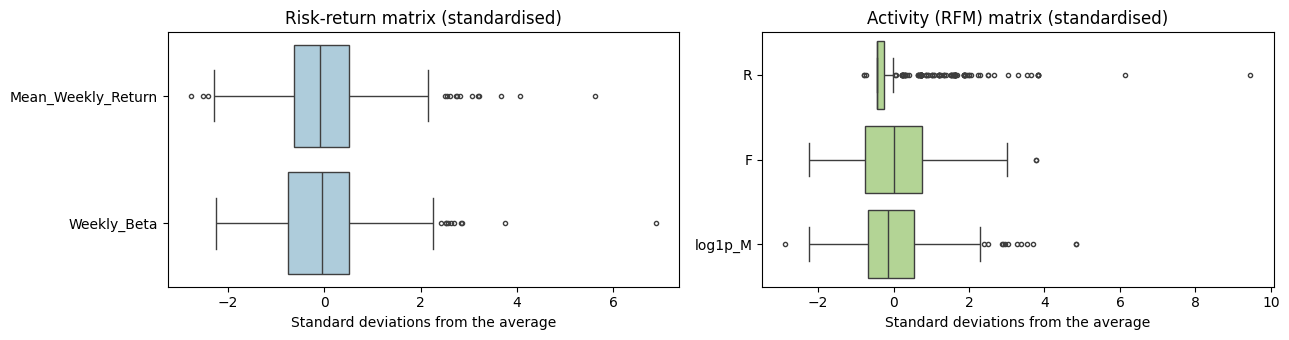

In [126]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
sns.boxplot(data=X_rr, orient="h", ax=axes[0], color="#a6cee3", fliersize=3)
axes[0].set_title("Risk-return matrix (standardised)"); axes[0].set_xlabel("Standard deviations from the average")
sns.boxplot(data=X_rfm, orient="h", ax=axes[1], color="#b2df8a", fliersize=3)
axes[1].set_title("Activity (RFM) matrix (standardised)"); axes[1].set_xlabel("Standard deviations from the average")
plt.tight_layout()
save_fig("g9_standardised_boxplots")
plt.show()

**Agglomerative clustering**

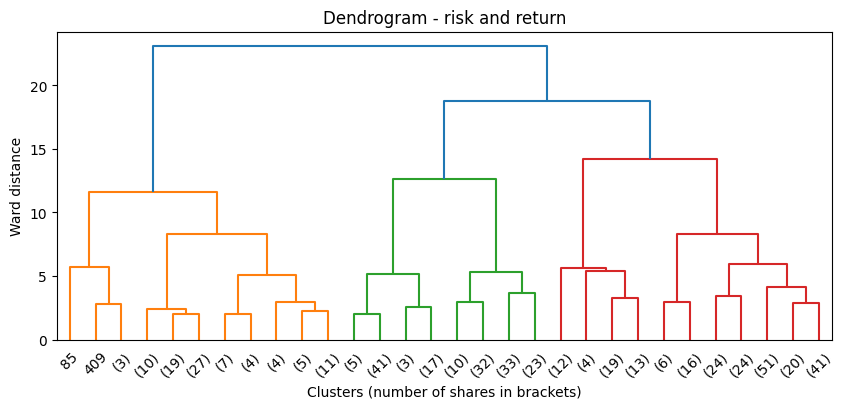

In [127]:
Z_rr = linkage(X_rr, method="ward")
Z_rfm = linkage(X_rfm, method="ward")

plt.figure(figsize=(10, 4))
dendrogram(Z_rr, truncate_mode="lastp", p=30, leaf_rotation=45)
plt.title("Dendrogram - risk and return")
plt.xlabel("Clusters (number of shares in brackets)")
plt.ylabel("Ward distance")
plt.savefig("outputs/fig_dendrogram_risk_return.png", dpi=150, bbox_inches="tight")
plt.show()

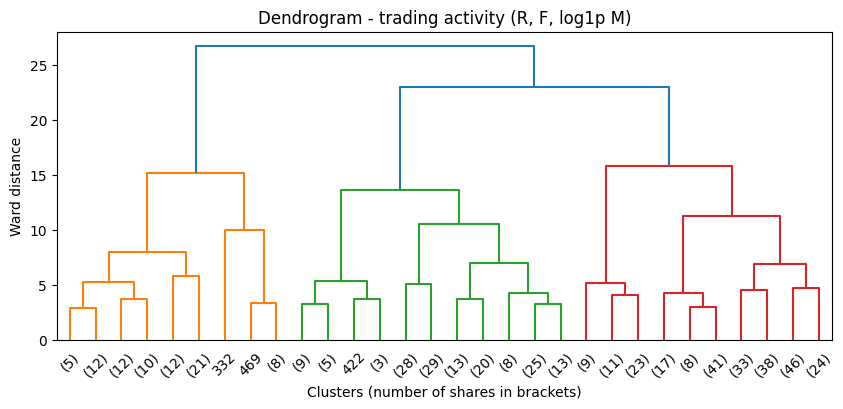

In [128]:
plt.figure(figsize=(10, 4))
dendrogram(Z_rfm, truncate_mode="lastp", p=30, leaf_rotation=45)
plt.title("Dendrogram - trading activity (R, F, log1p M)")
plt.xlabel("Clusters (number of shares in brackets)")
plt.ylabel("Ward distance")
plt.savefig("outputs/fig_dendrogram_rfm.png", dpi=150, bbox_inches="tight")
plt.show()

In [129]:
ward_rows = []
for name, X, Z in [("Risk_Return", X_rr, Z_rr), ("RFM", X_rfm, Z_rfm)]:
    for k in range(2, 9):
        labels = cut_tree(Z, n_clusters=k).ravel() + 1
        sil = silhouette_score(X, labels)
        sizes = np.bincount(labels)[1:]
        ward_rows.append([name, k, round(sil, 3), sizes.tolist()])

ward_table = pd.DataFrame(ward_rows, columns=["Matrix", "k", "Silhouette", "Cluster_sizes"])
print(ward_table.to_string(index=False))
ward_table.to_csv("outputs/ward_k_comparison.csv", index=False)

     Matrix  k  Silhouette                     Cluster_sizes
Risk_Return  2       0.339                         [394, 92]
Risk_Return  3       0.274                    [230, 164, 92]
Risk_Return  4       0.282                [182, 164, 48, 92]
Risk_Return  5       0.304             [182, 66, 98, 48, 92]
Risk_Return  6       0.320          [182, 66, 98, 48, 87, 5]
Risk_Return  7       0.324      [160, 66, 98, 48, 22, 87, 5]
Risk_Return  8       0.321  [160, 66, 98, 48, 22, 56, 31, 5]
        RFM  2       0.368                         [404, 82]
        RFM  3       0.304                    [154, 250, 82]
        RFM  4       0.289                [154, 207, 82, 43]
        RFM  5       0.305            [154, 207, 72, 43, 10]
        RFM  6       0.314        [136, 207, 18, 72, 43, 10]
        RFM  7       0.292    [136, 66, 18, 72, 141, 43, 10]
        RFM  8       0.302 [57, 66, 79, 18, 72, 141, 43, 10]


**K-means clustering**

In [130]:
km_rows = []
for name, X in [("Risk_Return", X_rr), ("RFM", X_rfm)]:
    for k in range(2, 9):
        km = KMeans(n_clusters=k, random_state=random_seed, n_init=20)
        labels = km.fit_predict(X) + 1
        sil = silhouette_score(X, labels)
        sizes = np.bincount(labels)[1:]
        km_rows.append([name, k, round(sil, 3), round(km.inertia_, 1), sizes.tolist()])

km_table = pd.DataFrame(km_rows, columns=["Matrix", "k", "Silhouette", "Inertia", "Cluster_sizes"])
print(km_table.to_string(index=False))
km_table.to_csv("outputs/kmeans_k_comparison.csv", index=False)

     Matrix  k  Silhouette  Inertia                     Cluster_sizes
Risk_Return  2       0.387    621.6                        [143, 343]
Risk_Return  3       0.329    461.2                   [202, 165, 119]
Risk_Return  4       0.327    371.6               [132, 154, 40, 160]
Risk_Return  5       0.341    309.6           [112, 166, 131, 27, 50]
Risk_Return  6       0.334    265.4        [56, 113, 158, 111, 43, 5]
Risk_Return  7       0.331    227.5      [83, 74, 143, 85, 5, 48, 48]
Risk_Return  8       0.354    194.4  [136, 43, 76, 78, 5, 29, 40, 79]
        RFM  2       0.423   1066.8                         [418, 68]
        RFM  3       0.325    796.6                    [270, 152, 64]
        RFM  4       0.341    609.8                [122, 61, 212, 91]
        RFM  5       0.358    514.7            [68, 122, 87, 11, 198]
        RFM  6       0.346    437.4       [104, 120, 141, 69, 11, 41]
        RFM  7       0.347    386.3    [141, 41, 104, 120, 1, 68, 11]
        RFM  8      

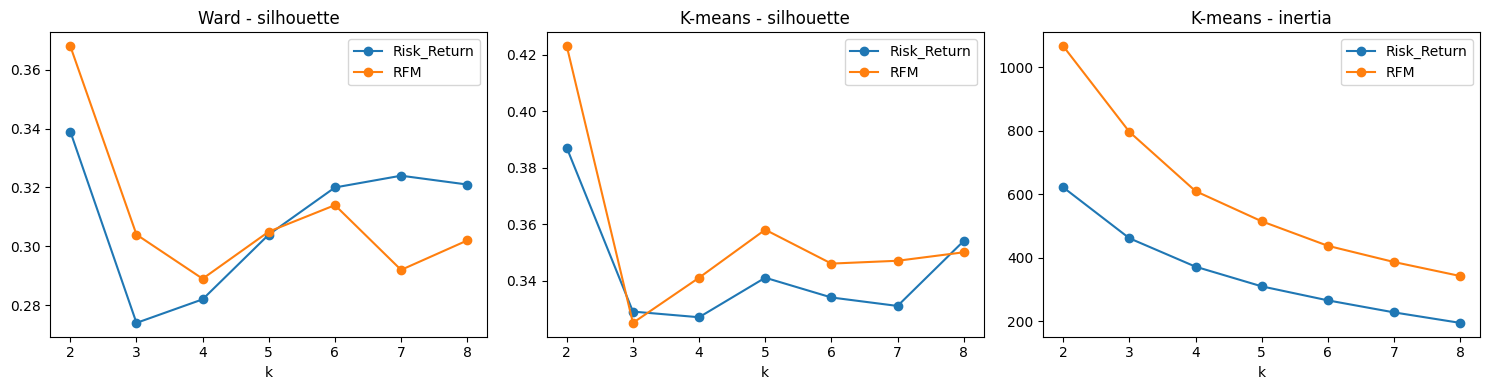

In [131]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name in ["Risk_Return", "RFM"]:
    w = ward_table[ward_table["Matrix"] == name]
    m = km_table[km_table["Matrix"] == name]
    axes[0].plot(w["k"], w["Silhouette"], marker="o", label=name)
    axes[1].plot(m["k"], m["Silhouette"], marker="o", label=name)
    axes[2].plot(m["k"], m["Inertia"], marker="o", label=name)
axes[0].set_title("Ward - silhouette")
axes[1].set_title("K-means - silhouette")
axes[2].set_title("K-means - inertia")
for ax in axes:
    ax.set_xlabel("k")
    ax.legend()
plt.tight_layout()
plt.savefig("outputs/fig_choose_k.png", dpi=150)
plt.show()

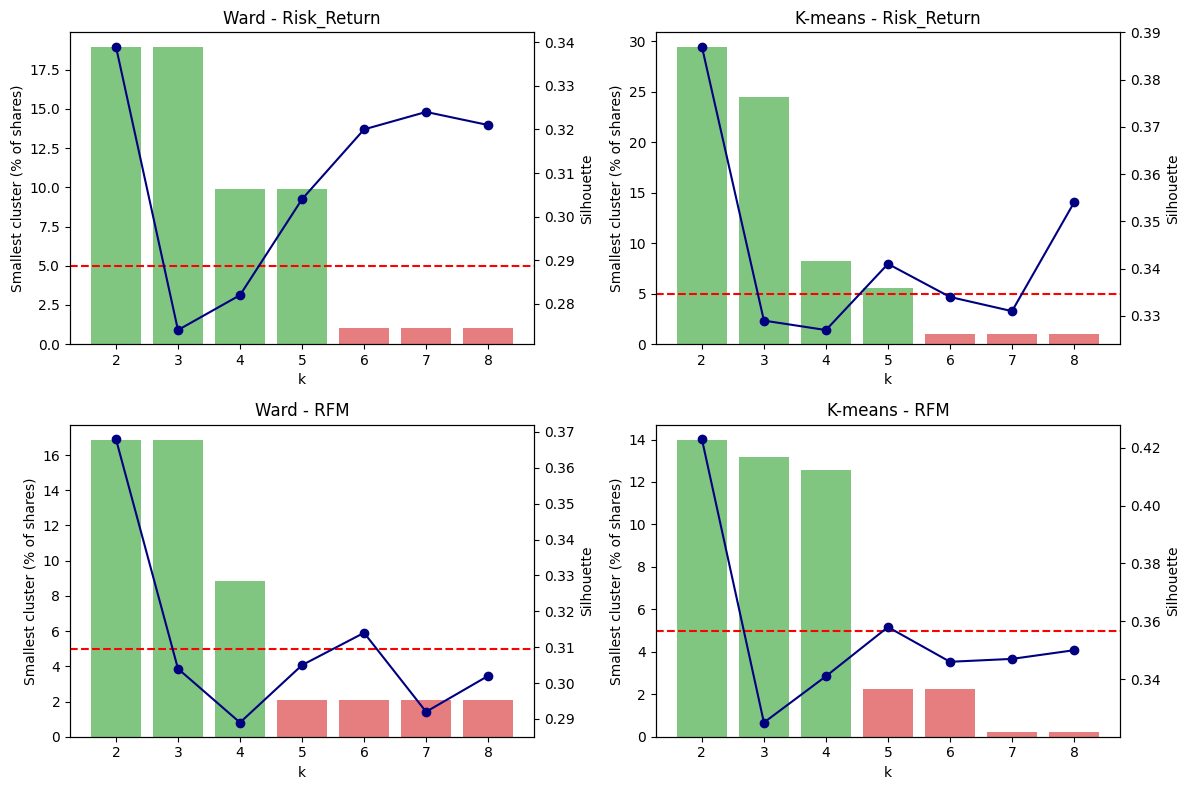

In [132]:
MIN_PCT = 5
n_sh = len(features)

def add_min_pct(tbl):
    t = tbl.copy()
    t["Smallest_pct"] = t["Cluster_sizes"].apply(lambda s: min(s) / n_sh * 100)
    return t

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for r, mat in enumerate(["Risk_Return", "RFM"]):
    for c, (name, tbl) in enumerate([("Ward", add_min_pct(ward_table)), ("K-means", add_min_pct(km_table))]):
        d = tbl[tbl["Matrix"] == mat]
        ax = axes[r, c]
        ax.bar(d["k"], d["Smallest_pct"], color=["tab:green" if v >= MIN_PCT else "tab:red" for v in d["Smallest_pct"]], alpha=0.6)
        ax.axhline(MIN_PCT, color="red", ls="--")
        ax.set_xlabel("k"); ax.set_ylabel("Smallest cluster (% of shares)"); ax.set_title(f"{name} - {mat}")
        ax2 = ax.twinx()
        ax2.plot(d["k"], d["Silhouette"], "o-", color="navy"); ax2.set_ylabel("Silhouette"); ax2.grid(False)
plt.tight_layout()
save_fig("g10_choose_k")
plt.show()

Choose k

In [133]:
k_ward_rr = 3
k_ward_rfm = 3
k_km_rr = 3
k_km_rfm = 3

features["Ward_RR"] = cut_tree(Z_rr, n_clusters=k_ward_rr).ravel() + 1
features["Ward_RFM"] = cut_tree(Z_rfm, n_clusters=k_ward_rfm).ravel() + 1
features["KM_RR"] = KMeans(n_clusters=k_km_rr, random_state=random_seed, n_init=20).fit_predict(X_rr) + 1
features["KM_RFM"] = KMeans(n_clusters=k_km_rfm, random_state=random_seed, n_init=20).fit_predict(X_rfm) + 1

for col in ["Ward_RR", "KM_RR", "Ward_RFM", "KM_RFM"]:
    print(col, "cluster sizes:", np.bincount(features[col])[1:].tolist())

Ward_RR cluster sizes: [230, 164, 92]
KM_RR cluster sizes: [202, 165, 119]
Ward_RFM cluster sizes: [154, 250, 82]
KM_RFM cluster sizes: [270, 152, 64]


**Cluster profiles and algorithm comparison**

In [134]:
for col in ["Ward_RR", "KM_RR"]:
    print("\nProfile:", col)
    profile = features.groupby(col)[["Mean_Weekly_Return", "Weekly_Beta"]].mean().round(4)
    profile["N_Shares"] = features.groupby(col).size()
    print(profile)

for col in ["Ward_RFM", "KM_RFM"]:
    print("\nProfile:", col)
    profile = features.groupby(col)[["R", "F", "M"]].mean().round(2)
    profile["N_Shares"] = features.groupby(col).size()
    print(profile)


Profile: Ward_RR
         Mean_Weekly_Return  Weekly_Beta  N_Shares
Ward_RR                                           
1                    0.0015       1.1096       230
2                    0.0029       0.6012       164
3                    0.0063       1.2981        92

Profile: KM_RR
       Mean_Weekly_Return  Weekly_Beta  N_Shares
KM_RR                                           
1                  0.0026       0.6308       202
2                  0.0009       1.1391       165
3                  0.0060       1.3264       119

Profile: Ward_RFM
              R     F             M  N_Shares
Ward_RFM                                     
1         13.68  2.86  8.014525e+10       154
2         12.12  3.36  1.176413e+10       250
3         58.30  2.10  4.715898e+10        82

Profile: KM_RFM
            R     F             M  N_Shares
KM_RFM                                     
1       13.37  3.35  1.201394e+10       270
2       14.30  2.89  8.172911e+10       152
3       64.61  1.69  5.4

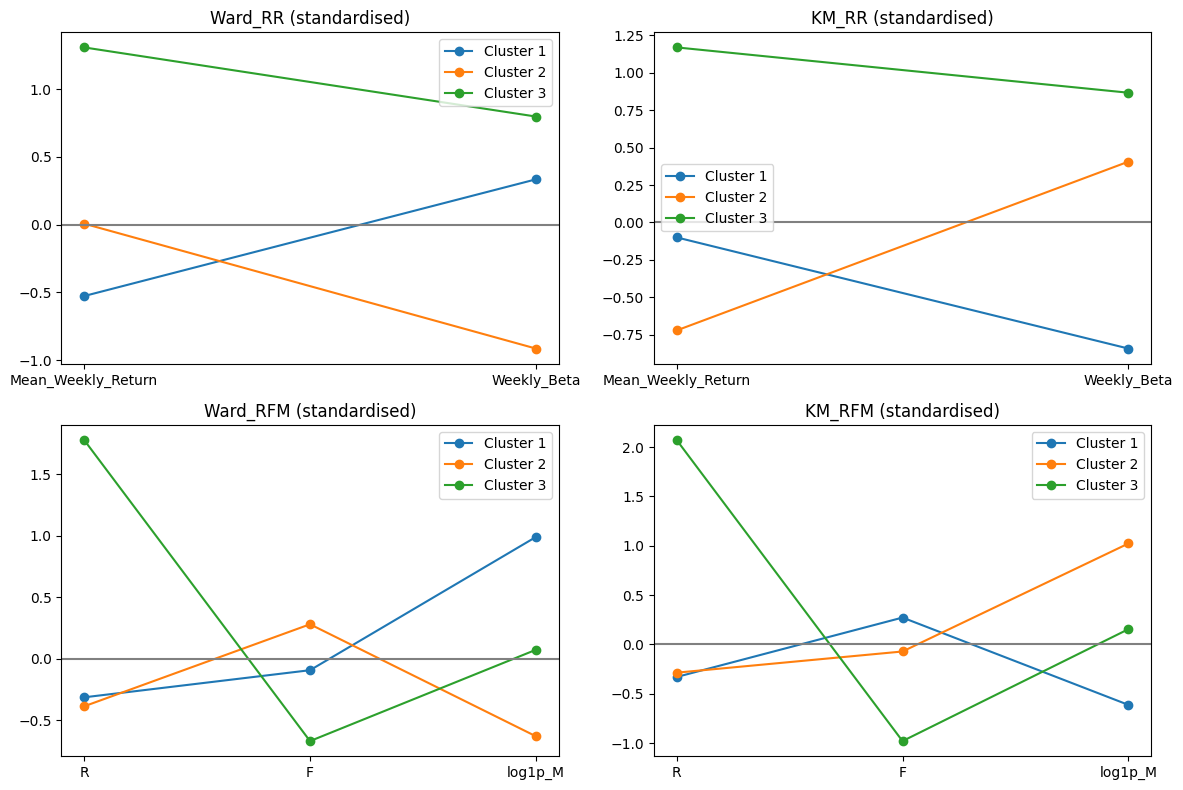

In [135]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
solutions = [("Ward_RR", X_rr), ("KM_RR", X_rr), ("Ward_RFM", X_rfm), ("KM_RFM", X_rfm)]
for ax, (col, X) in zip(axes.ravel(), solutions):
    means = X.groupby(features[col].values).mean()
    for c in means.index:
        ax.plot(means.columns, means.loc[c], marker="o", label="Cluster " + str(c))
    ax.axhline(0, color="grey")
    ax.set_title(col + " (standardised)")
    ax.legend()
plt.tight_layout()
plt.savefig("outputs/fig_standardised_profiles.png", dpi=150)
plt.show()

In [136]:
pca = PCA(n_components=2, random_state=random_seed)
pcs = pca.fit_transform(X_rfm)
print("PCA explained variance:", pca.explained_variance_ratio_.round(3))
print()
print(pd.DataFrame(pca.components_.T, index=X_rfm.columns, columns=["PC1", "PC2"]).round(3))

PCA explained variance: [0.458 0.336]

           PC1    PC2
R        0.711  0.023
F       -0.650  0.402
log1p_M  0.268  0.915


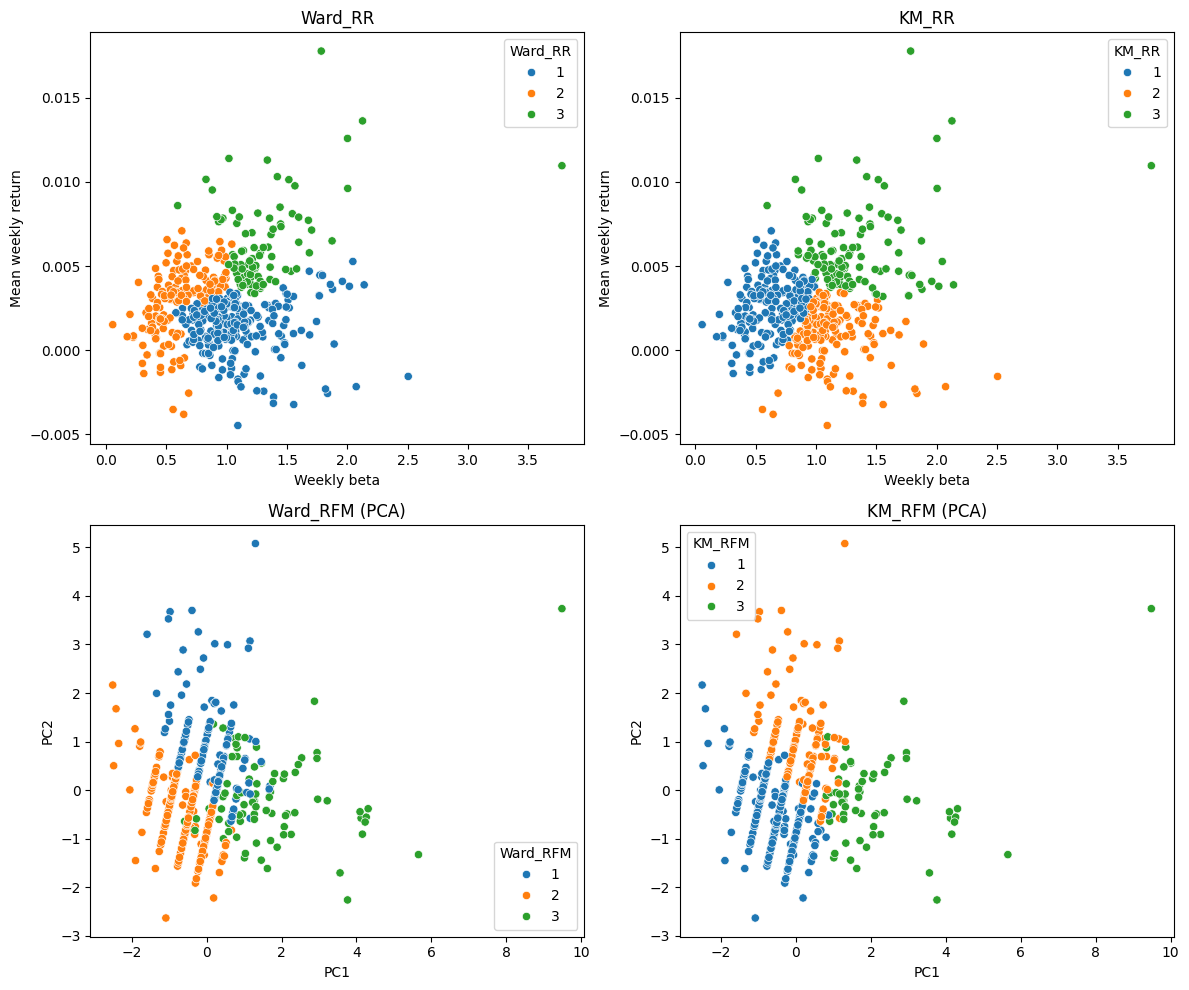

In [137]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, col in zip(axes[0], ["Ward_RR", "KM_RR"]):
    sns.scatterplot(x=features["Weekly_Beta"], y=features["Mean_Weekly_Return"], hue=features[col], palette="tab10", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Weekly beta")
    ax.set_ylabel("Mean weekly return")
for ax, col in zip(axes[1], ["Ward_RFM", "KM_RFM"]):
    sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=features[col], palette="tab10", ax=ax)
    ax.set_title(col + " (PCA)")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
plt.tight_layout()
plt.savefig("outputs/fig_cluster_scatter.png", dpi=150)
plt.show()

In [138]:
print(f"ARI Ward vs K-means (risk and return): {round(adjusted_rand_score(features['Ward_RR'], features['KM_RR']), 3)}")
print(f"ARI Ward vs K-means (RFM): {round(adjusted_rand_score(features['Ward_RFM'], features['KM_RFM']), 3)}\n")
print(pd.crosstab(features["Ward_RR"], features["KM_RR"]), "\n")
print(pd.crosstab(features["Ward_RFM"], features["KM_RFM"]))

ARI Ward vs K-means (risk and return): 0.516
ARI Ward vs K-means (RFM): 0.834

KM_RR      1    2   3
Ward_RR              
1         54  160  16
2        148    3  13
3          0    2  90 

KM_RFM      1    2   3
Ward_RFM              
1           5  144   5
2         250    0   0
3          15    8  59


In [139]:
print("ARI risk/return (Ward) vs RFM (Ward):", round(adjusted_rand_score(features["Ward_RR"], features["Ward_RFM"]), 3))
print(pd.crosstab(features["Ward_RR"], features["Ward_RFM"]))
print("\nSector mix of each risk/return cluster (column %):")
print(pd.crosstab(features["GICS Sector"], features["Ward_RR"], normalize="columns").round(2))
print("\nSector mix of each RFM cluster (column %):")
print(pd.crosstab(features["GICS Sector"], features["Ward_RFM"], normalize="columns").round(2))

ARI risk/return (Ward) vs RFM (Ward): 0.024
Ward_RFM   1    2   3
Ward_RR              
1         59  134  37
2         58   80  26
3         37   36  19

Sector mix of each risk/return cluster (column %):
Ward_RR                    1     2     3
GICS Sector                             
Communication Services  0.03  0.05  0.05
Consumer Discretionary  0.12  0.05  0.12
Consumer Staples        0.02  0.16  0.00
Energy                  0.00  0.10  0.04
Financials              0.13  0.18  0.14
Health Care             0.13  0.16  0.02
Industrials             0.19  0.08  0.23
Information Technology  0.19  0.01  0.32
Materials               0.07  0.02  0.03
Real Estate             0.10  0.02  0.03
Utilities               0.02  0.15  0.01

Sector mix of each RFM cluster (column %):
Ward_RFM                   1     2     3
GICS Sector                             
Communication Services  0.06  0.03  0.05
Consumer Discretionary  0.13  0.07  0.11
Consumer Staples        0.07  0.06  0.09
Energy      

**RFM sensitivity and correlated inputs**

Correlation analysis

In [140]:
corr = X_rfm_raw.corr()
print(corr.round(3))

corr.to_csv("outputs/rfm_correlation.csv")

             R      F  log1p_M
R        1.000 -0.346    0.152
F       -0.346  1.000    0.013
log1p_M  0.152  0.013    1.000


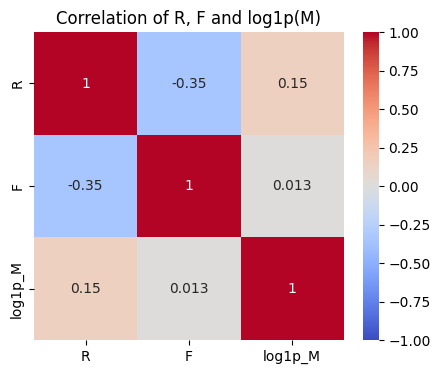

In [141]:
plt.figure(figsize=(5, 4))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation of R, F and log1p(M)")
plt.savefig("outputs/fig_rfm_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

Removal of Monetary

In [142]:
X_rf = StandardScaler().fit_transform(features[["R", "F"]])
Z_rf = linkage(X_rf, method="ward")
features["Ward_RF_only"] = cut_tree(Z_rf, n_clusters=k_ward_rfm).ravel() + 1

ari = adjusted_rand_score(features["Ward_RFM"], features["Ward_RF_only"])
print("k =", k_ward_rfm)
print("ARI between Ward RFM and Ward R,F only:", round(ari, 3))
print(pd.crosstab(features["Ward_RFM"], features["Ward_RF_only"]))

k = 3
ARI between Ward RFM and Ward R,F only: 0.291
Ward_RF_only    1   2   3
Ward_RFM                 
1              86  59   9
2             183  66   1
3               3   0  79


In [143]:
print("\nTraded value M by cluster - RFM solution:")
print(features.groupby("Ward_RFM")["M"].agg(["count", "median", "mean"]).round(0))
print("\nTraded value M by cluster - R,F only solution:")
print(features.groupby("Ward_RF_only")["M"].agg(["count", "median", "mean"]).round(0))


Traded value M by cluster - RFM solution:
          count        median          mean
Ward_RFM                                   
1           154  3.969545e+10  8.014525e+10
2           250  1.117761e+10  1.176413e+10
3            82  1.784903e+10  4.715898e+10

Traded value M by cluster - R,F only solution:
              count        median          mean
Ward_RF_only                                   
1               272  1.485534e+10  3.940097e+10
2               125  1.769899e+10  3.433790e+10
3                89  2.084781e+10  4.652963e+10


In [144]:
features.to_csv("outputs/feature_table_with_clusters.csv", index=False)
print(os.listdir("outputs"))

['fig_distributions.png', 'task3_adjclose_vs_close.csv', 'ward_k_comparison.csv', 'task3_sector_composition.csv', 'g9_standardised_boxplots.png', 'g16_rfm_overlap_and_distances.png', 'fig_rfm_correlation.png', 'g6_market_wide_breadth.png', 'g21_survivorship_check.png', 'g12_cluster_profiles_original_units.png', 'split_check.csv', 'g22_liquidity_proxy_limits.png', 'fig_choose_k.png', 'fig_dendrogram_rfm.png', 'feature_table_with_clusters_and_labels.csv', 'g7_worked_example.png', 'g2_exclusion_timeline.png', 'fig_standardised_profiles.png', 'g23_feature_persistence.png', 'task3_rfm_cluster_profile.csv', 'g4_beta_examples.png', 'provenance_manifest.json', 'g18_activity_monitoring.png', 'task3_activity_watchlist.csv', 'g3_return_beta_distributions.png', 'g_rfm_only_distributions.png', 'task3_rr_cluster_profile.csv', 'g8_feature_distributions.png', 'g14_sector_lift.png', 'fig_cluster_scatter.png', 'g10_choose_k.png', 'feature_table.csv', 'g20_price_adjustment_check.png', 'rfm_correlation.cs

# **Task 3 Business Intelligence and Critical Review**

**Data Mart Design**

In [145]:
calculation_version = "v1.0"
run_id = "RUN_" + datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
last60_dates = volume_v.index[-60:]
tk = features["Ticker"]

dim_time = pd.DataFrame({"Date": dates})
dim_time["Date_Key"] = dim_time["Date"].dt.strftime("%Y%m%d").astype(int)
dim_time["Year"] = dim_time["Date"].dt.year
dim_time["Quarter"] = dim_time["Date"].dt.quarter
dim_time["Month"] = dim_time["Date"].dt.month
dim_time["Week_Ending_Friday"] = dim_time["Date"].dt.to_period("W-FRI").dt.end_time.dt.normalize()
dim_time["In_Weekly_Return_Window"] = dim_time["Week_Ending_Friday"].isin(weekly_returns.index)
dim_time["In_Last_60_Sessions"] = dim_time["Date"].isin(last60_dates)

share_cols = [c for c in ["Symbol", "Security", "GICS Sector", "GICS Sub-Industry", "Date added"] if c in sp500.columns]
dim_share = sp500[share_cols].rename(columns={"Symbol": "Ticker", "GICS Sector": "Sector", "GICS Sub-Industry": "Sub_Industry",
                                              "Date added": "Date_Added_To_Index"}).copy()
if "Date_Added_To_Index" in dim_share.columns:
    dim_share["Date_Added_To_Index"] = dim_share["Date_Added_To_Index"].astype(str)
dim_share.insert(0, "Share_Key", range(1, len(dim_share) + 1))
first_reason = exclusion_df.drop_duplicates("Ticker").set_index("Ticker")["Reason"]
dim_share["Included_In_Clustering"] = dim_share["Ticker"].isin(tk)
dim_share["Exclusion_Reason"] = dim_share["Ticker"].map(first_reason).fillna("")
share_key = dict(zip(dim_share["Ticker"], dim_share["Share_Key"]))

dim_benchmark = pd.DataFrame([{"Benchmark_Key": 1, "Symbol": "^GSPC", "Name": "S&P 500 index", "Source": "yfinance",
                               "Return_Price_Basis": "Adj Close", "Frequency": "Daily, resampled to Friday-ending weeks"}])

dim_run = pd.DataFrame([{
    "Run_ID": run_id, "Calculation_Version": calculation_version,
    "Ticker_List_Retrieved_On": str(retrieval_date), "Study_Start": start_date, "Study_End_Exclusive": end_date,
    "Observation_Date": str(obs_date.date()), "Baseline_Sessions": 20, "Activity_Window_Sessions": 60,
    "High_Volume_Multiple": 2, "Return_Price_Basis": "Adj Close",
    "Monetary_Price_Basis": "Close (split-adjusted by Yahoo, not dividend-adjusted) x Volume",
    "Random_Seed": random_seed, "KMeans_n_init": 20, "Ward_Linkage": "ward / euclidean",
    "k_Ward_RR": k_ward_rr, "k_KM_RR": k_km_rr, "k_Ward_RFM": k_ward_rfm, "k_KM_RFM": k_km_rfm,
    "Shares_In_Ticker_List": len(tickers), "Shares_Clustered": len(features),
    "Python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
    "yfinance": yf.__version__, "scikit_learn": sklearn.__version__, "scipy": scipy.__version__}])

print("Run ID:", run_id, "| Calculation version:", calculation_version)
print("dim_time:", dim_time.shape, "| dim_share:", dim_share.shape)

Run ID: RUN_20261125_025217 | Calculation version: v1.0
dim_time: (1005, 8) | dim_share: (503, 8)


In [146]:
avg20_all = volume_v.shift(1).rolling(20).mean()
flags_all = volume_v > 2 * avg20_all


def to_long(df, name):
    out = df.rename_axis(index="Date").reset_index().melt(id_vars="Date", var_name="Ticker", value_name=name)
    return out


fact_daily = to_long(close_v, "Close")
for df_, name in [(adj_close_v, "Adj_Close"), (volume_v, "Volume"), (avg20_all, "Avg_Volume_Prev20"), (flags_all, "High_Volume_Flag")]:
    fact_daily = fact_daily.merge(to_long(df_, name), on=["Date", "Ticker"])

fact_daily["Traded_Value_USD"] = fact_daily["Close"] * fact_daily["Volume"]
fact_daily["High_Volume_Threshold"] = 2 * fact_daily["Avg_Volume_Prev20"]
fact_daily["High_Volume_Flag"] = fact_daily["High_Volume_Flag"].astype(int)
fact_daily["Date_Key"] = fact_daily["Date"].dt.strftime("%Y%m%d").astype(int)
fact_daily["Share_Key"] = fact_daily["Ticker"].map(share_key)
fact_daily["Benchmark_Key"] = 1
fact_daily["Calculation_Version"] = calculation_version
fact_daily = fact_daily[["Date_Key", "Share_Key", "Benchmark_Key", "Close", "Adj_Close", "Volume", "Traded_Value_USD",
                         "High_Volume_Threshold", "High_Volume_Flag", "Calculation_Version"]]

fact_bench = bench[["Close", "Adj Close", "Volume"]].rename(columns={"Adj Close": "Adj_Close"}).rename_axis(index="Date").reset_index()
fact_bench["Date_Key"] = fact_bench["Date"].dt.strftime("%Y%m%d").astype(int)
fact_bench["Benchmark_Key"] = 1
fact_bench = fact_bench[["Date_Key", "Benchmark_Key", "Close", "Adj_Close", "Volume"]]

fact_weekly = to_long(weekly_returns[valid_tickers].rename_axis(index="Date"), "Weekly_Return").rename(columns={"Date": "Week_Ending"})
fact_weekly["Benchmark_Return"] = fact_weekly["Week_Ending"].map(bench_returns)
fact_weekly["Share_Key"] = fact_weekly["Ticker"].map(share_key)
fact_weekly["Benchmark_Key"] = 1
fact_weekly["Week_Key"] = fact_weekly["Week_Ending"].dt.strftime("%Y%m%d").astype(int)
fact_weekly["Calculation_Version"] = calculation_version
fact_weekly = fact_weekly[["Week_Key", "Share_Key", "Benchmark_Key", "Weekly_Return", "Benchmark_Return", "Calculation_Version"]]

fact_feature = features[["Ticker", "Mean_Weekly_Return", "Weekly_Beta", "N_Weeks", "R", "F", "M"]].copy()
fact_feature["log1p_M"] = np.log1p(fact_feature["M"])
fact_feature["Share_Key"] = fact_feature["Ticker"].map(share_key)
fact_feature["Run_ID"] = run_id
fact_feature = fact_feature.drop(columns="Ticker")

solutions = {"Ward_RR": ("Risk_Return", "Ward", k_ward_rr), "KM_RR": ("Risk_Return", "KMeans", k_km_rr),
             "Ward_RFM": ("RFM", "Ward", k_ward_rfm), "KM_RFM": ("RFM", "KMeans", k_km_rfm),
             "Ward_RF_only": ("RF_only_sensitivity", "Ward", k_ward_rfm)}
assign_rows = []
for col, (matrix, algo, k) in solutions.items():
    tmp = features[["Ticker", col]].rename(columns={col: "Cluster_Label"})
    tmp["Solution_ID"], tmp["Feature_Matrix"], tmp["Algorithm"], tmp["k"], tmp["Run_ID"] = col, matrix, algo, k, run_id
    assign_rows.append(tmp)
fact_cluster = pd.concat(assign_rows, ignore_index=True)
fact_cluster["Share_Key"] = fact_cluster["Ticker"].map(share_key)
fact_cluster = fact_cluster.drop(columns="Ticker")

print("fact_daily_share:", fact_daily.shape, "| fact_daily_benchmark:", fact_bench.shape)
print("fact_weekly_return:", fact_weekly.shape, "| fact_share_feature:", fact_feature.shape, "| fact_cluster_assignment:", fact_cluster.shape)


fact_daily_share: (488430, 10) | fact_daily_benchmark: (1005, 5)
fact_weekly_return: (100602, 6) | fact_share_feature: (486, 9) | fact_cluster_assignment: (2430, 7)


In [147]:
db_path = "data/crm_datamart.db"
con = sqlite3.connect(db_path)

replace_tables = {"dim_time": dim_time, "dim_share": dim_share, "dim_benchmark": dim_benchmark,
                  "fact_daily_share": fact_daily, "fact_daily_benchmark": fact_bench, "fact_weekly_return": fact_weekly}
append_tables = {"dim_run": dim_run, "fact_share_feature": fact_feature, "fact_cluster_assignment": fact_cluster}

for mode, group in [("replace", replace_tables), ("append", append_tables)]:
    for name, df_ in group.items():
        out = df_.copy()
        for c in out.columns:
            if pd.api.types.is_datetime64_any_dtype(out[c]):
                out[c] = out[c].dt.strftime("%Y-%m-%d")
        out.to_sql(name, con, index=False, if_exists=mode)
con.commit()

counts = {n: con.execute(f"SELECT COUNT(*) FROM {n}").fetchone()[0] for n in list(replace_tables) + list(append_tables)}
print(pd.Series(counts, name="Rows").to_string())

dim_time                     1005
dim_share                     503
dim_benchmark                   1
fact_daily_share           488430
fact_daily_benchmark         1005
fact_weekly_return         100602
dim_run                         2
fact_share_feature            972
fact_cluster_assignment      4860


In [148]:
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()


files_to_hash = [p for p in sorted(glob("data/*") + glob("outputs/*.csv")) if os.path.isfile(p)]
manifest = {"run": dim_run.iloc[0].to_dict(), "file_sha256": {p: sha256(p) for p in files_to_hash}}
with open("outputs/provenance_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2, default=str)
print("Files hashed:", len(files_to_hash))
print(pd.Series(manifest["run"]).to_string())

Files hashed: 24
Run_ID                                                    RUN_20261125_025217
Calculation_Version                                                      v1.0
Ticker_List_Retrieved_On                                           2026-11-25
Study_Start                                                        2021-01-01
Study_End_Exclusive                                                2025-01-01
Observation_Date                                                   2024-12-31
Baseline_Sessions                                                          20
Activity_Window_Sessions                                                   60
High_Volume_Multiple                                                        2
Return_Price_Basis                                                  Adj Close
Monetary_Price_Basis        Close (split-adjusted by Yahoo, not dividend-a...
Random_Seed                                                                42
KMeans_n_init                                  

In [149]:
q_sector = """
SELECT s.Sector, c.Cluster_Label AS RFM_Cluster, COUNT(*) AS N_Shares,
       ROUND(AVG(f.Weekly_Beta), 3) AS Avg_Beta, ROUND(AVG(f.M) / 1e9, 2) AS Avg_M_Billion
FROM fact_cluster_assignment c
JOIN dim_share s ON s.Share_Key = c.Share_Key
JOIN fact_share_feature f ON f.Share_Key = c.Share_Key AND f.Run_ID = c.Run_ID
WHERE c.Run_ID = ? AND c.Solution_ID = 'Ward_RFM'
GROUP BY s.Sector, c.Cluster_Label
ORDER BY s.Sector, c.Cluster_Label
"""
display(pd.read_sql(q_sector, con, params=[run_id]).head(12))

q_breadth = """
SELECT t.Date, ROUND(100.0 * SUM(d.High_Volume_Flag) / COUNT(*), 2) AS Pct_Shares_High_Volume
FROM fact_daily_share d
JOIN dim_time t ON t.Date_Key = d.Date_Key
WHERE d.High_Volume_Threshold IS NOT NULL
GROUP BY t.Date
ORDER BY Pct_Shares_High_Volume DESC
LIMIT 5
"""
display(pd.read_sql(q_breadth, con))
con.close()

,Sector,RFM_Cluster,N_Shares,Avg_Beta,Avg_M_Billion
0,Communication Services,1,9,0.847,132.35
1,Communication Services,2,7,0.744,6.60
2,Communication Services,3,4,1.142,48.31
3,Consumer Discretionary,1,20,1.207,149.81
4,Consumer Discretionary,2,18,1.164,14.12
5,Consumer Discretionary,3,9,1.369,25.38
6,Consumer Staples,1,11,0.509,49.00
7,Consumer Staples,2,14,0.491,13.07
8,Consumer Staples,3,7,0.611,18.12
9,Energy,1,10,0.676,38.73


,Date,Pct_Shares_High_Volume
0,2024-12-20,72.84
1,2023-12-15,65.64
2,2024-09-20,63.79
3,2022-12-16,58.23
4,2021-09-17,57.00


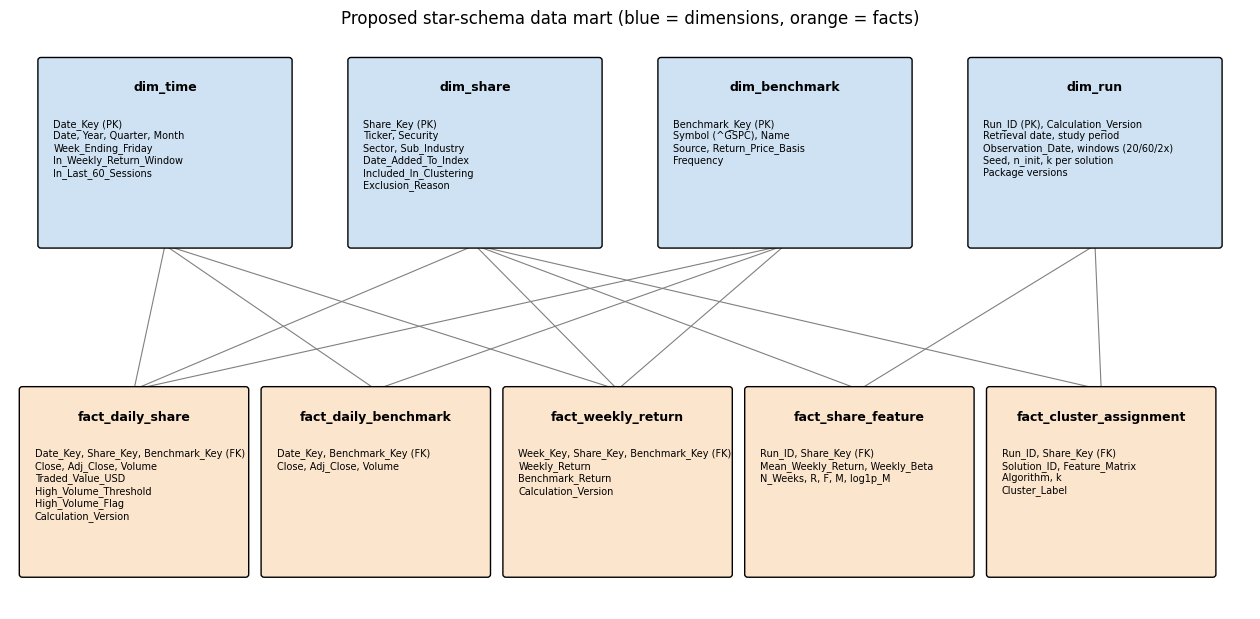

In [150]:
def draw_box(ax, x, y, w, h, title, lines, colour):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=colour, ec="black", lw=1, zorder=3))
    ax.text(x + w / 2, y + h - 0.35, title, ha="center", va="top", fontsize=9, fontweight="bold", zorder=4)
    ax.text(x + 0.2, y + h - 1.0, "\n".join(lines), ha="left", va="top", fontsize=7, zorder=4)


fig, ax = plt.subplots(figsize=(16, 7.5))
ax.set_xlim(0, 20); ax.set_ylim(0, 10); ax.axis("off")

dims = {"dim_time": (0.5, ["Date_Key (PK)", "Date, Year, Quarter, Month", "Week_Ending_Friday", "In_Weekly_Return_Window", "In_Last_60_Sessions"]),
        "dim_share": (5.5, ["Share_Key (PK)", "Ticker, Security", "Sector, Sub_Industry", "Date_Added_To_Index", "Included_In_Clustering", "Exclusion_Reason"]),
        "dim_benchmark": (10.5, ["Benchmark_Key (PK)", "Symbol (^GSPC), Name", "Source, Return_Price_Basis", "Frequency"]),
        "dim_run": (15.5, ["Run_ID (PK), Calculation_Version", "Retrieval date, study period", "Observation_Date, windows (20/60/2x)", "Seed, n_init, k per solution", "Package versions"])}
facts = {"fact_daily_share": (0.2, ["Date_Key, Share_Key, Benchmark_Key (FK)", "Close, Adj_Close, Volume", "Traded_Value_USD", "High_Volume_Threshold", "High_Volume_Flag", "Calculation_Version"], ["dim_time", "dim_share", "dim_benchmark"]),
         "fact_daily_benchmark": (4.1, ["Date_Key, Benchmark_Key (FK)", "Close, Adj_Close, Volume"], ["dim_time", "dim_benchmark"]),
         "fact_weekly_return": (8.0, ["Week_Key, Share_Key, Benchmark_Key (FK)", "Weekly_Return", "Benchmark_Return", "Calculation_Version"], ["dim_time", "dim_share", "dim_benchmark"]),
         "fact_share_feature": (11.9, ["Run_ID, Share_Key (FK)", "Mean_Weekly_Return, Weekly_Beta", "N_Weeks, R, F, M, log1p_M"], ["dim_run", "dim_share"]),
         "fact_cluster_assignment": (15.8, ["Run_ID, Share_Key (FK)", "Solution_ID, Feature_Matrix", "Algorithm, k", "Cluster_Label"], ["dim_run", "dim_share"])}
dim_w, dim_h, fact_w, fact_h = 4.0, 3.2, 3.6, 3.2
dim_y, fact_y = 6.3, 0.6

for name, (x, cols) in dims.items():
    draw_box(ax, x, dim_y, dim_w, dim_h, name, cols, "#cfe2f3")
for name, (x, cols, links) in facts.items():
    draw_box(ax, x, fact_y, fact_w, fact_h, name, cols, "#fce5cd")
    for d in links:
        dx = dims[d][0] + dim_w / 2
        ax.plot([x + fact_w / 2, dx], [fact_y + fact_h, dim_y], color="grey", lw=0.8, zorder=1)
ax.set_title("Proposed star-schema data mart (blue = dimensions, orange = facts)")
save_fig("g11_data_mart_star_schema")
plt.show()

**Review of results and Visualization**

Cluster Profiles and Sector Composition

In [151]:
def cluster_names(col, rank_col, tags):
    order = features.groupby(col)[rank_col].median().sort_values().index.tolist()
    if len(order) != len(tags):
        tags = [f"rank {i + 1}" for i in range(len(order))]
    return {c: f"C{c}: {tag}" for c, tag in zip(order, tags)}

rr_names = cluster_names("Ward_RR", "Weekly_Beta", ["lowest beta", "middle beta", "highest beta"])
rfm_names = cluster_names("Ward_RFM", "M", ["lowest traded value", "middle traded value", "highest traded value"])
rr_order, rfm_order = list(rr_names.values()), list(rfm_names.values())

features["RR_Label"] = features["Ward_RR"].map(rr_names)
features["RFM_Label"] = features["Ward_RFM"].map(rfm_names)
features["Return_pct"] = features["Mean_Weekly_Return"] * 100
features["M_Billion"] = features["M"] / 1e9
features["log10_M"] = np.log10(features["M"])

rr_profile = features.groupby("RR_Label").agg(N_Shares=("Ticker", "size"), Mean_Weekly_Return_pct=("Return_pct", "mean"),
                                              Mean_Beta=("Weekly_Beta", "mean"), Median_Beta=("Weekly_Beta", "median")).reindex(rr_order)
rfm_profile = features.groupby("RFM_Label").agg(N_Shares=("Ticker", "size"), Median_R_days=("R", "median"), Median_F_days=("F", "median"),
                                                Median_M_Billion=("M_Billion", "median"), Mean_M_Billion=("M_Billion", "mean")).reindex(rfm_order)
print("Risk and return clusters (Ward, original units)")
print(rr_profile.round(3))
print("\nRFM clusters (Ward, original units)")
print(rfm_profile.round(2))

Risk and return clusters (Ward, original units)
                  N_Shares  Mean_Weekly_Return_pct  Mean_Beta  Median_Beta
RR_Label                                                                  
C2: lowest beta        164                   0.287      0.601        0.578
C1: middle beta        230                   0.146      1.110        1.038
C3: highest beta        92                   0.632      1.298        1.218

RFM clusters (Ward, original units)
                          N_Shares  Median_R_days  Median_F_days  \
RFM_Label                                                          
C2: lowest traded value        250           11.0            3.0   
C3: middle traded value         82           54.5            2.0   
C1: highest traded value       154           11.0            3.0   

                          Median_M_Billion  Mean_M_Billion  
RFM_Label                                                   
C2: lowest traded value              11.18           11.76  
C3: middle trade

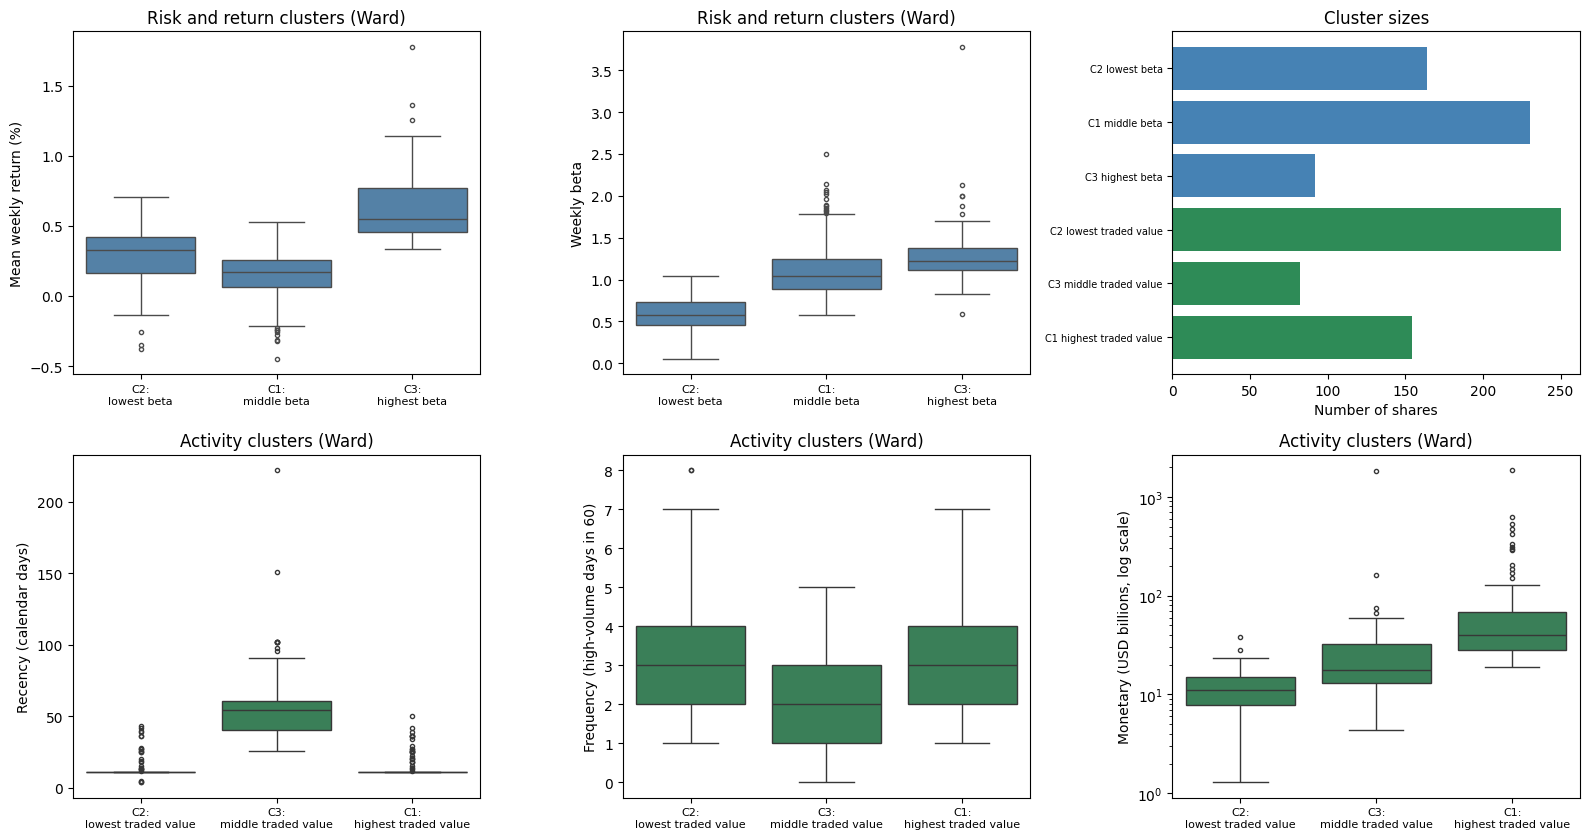

In [152]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
panels = [(axes[0, 0], "Return_pct", "Mean weekly return (%)", rr_order, "RR_Label", False),
          (axes[0, 1], "Weekly_Beta", "Weekly beta", rr_order, "RR_Label", False),
          (axes[1, 0], "R", "Recency (calendar days)", rfm_order, "RFM_Label", False),
          (axes[1, 1], "F", "Frequency (high-volume days in 60)", rfm_order, "RFM_Label", False),
          (axes[1, 2], "M_Billion", "Monetary (USD billions, log scale)", rfm_order, "RFM_Label", True)]
for ax, col, ylabel, order, grp, logy in panels:
    sns.boxplot(data=features, x=grp, y=col, order=order, color="steelblue" if grp == "RR_Label" else "seagreen", fliersize=3, ax=ax)
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel(""); ax.set_ylabel(ylabel)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([o.replace(": ", ":\n") for o in order], fontsize=8)
axes[0, 0].set_title("Risk and return clusters (Ward)"); axes[0, 1].set_title("Risk and return clusters (Ward)")
axes[1, 0].set_title("Activity clusters (Ward)"); axes[1, 1].set_title("Activity clusters (Ward)"); axes[1, 2].set_title("Activity clusters (Ward)")
sizes = pd.concat([rr_profile["N_Shares"], rfm_profile["N_Shares"]])
axes[0, 2].barh([s.replace(": ", " ") for s in sizes.index][::-1], sizes.values[::-1],
                color=["seagreen"] * len(rfm_order) + ["steelblue"] * len(rr_order))
axes[0, 2].set_xlabel("Number of shares"); axes[0, 2].set_title("Cluster sizes")
axes[0, 2].tick_params(axis="y", labelsize=7)
plt.tight_layout()
save_fig("g12_cluster_profiles_original_units")
plt.show()

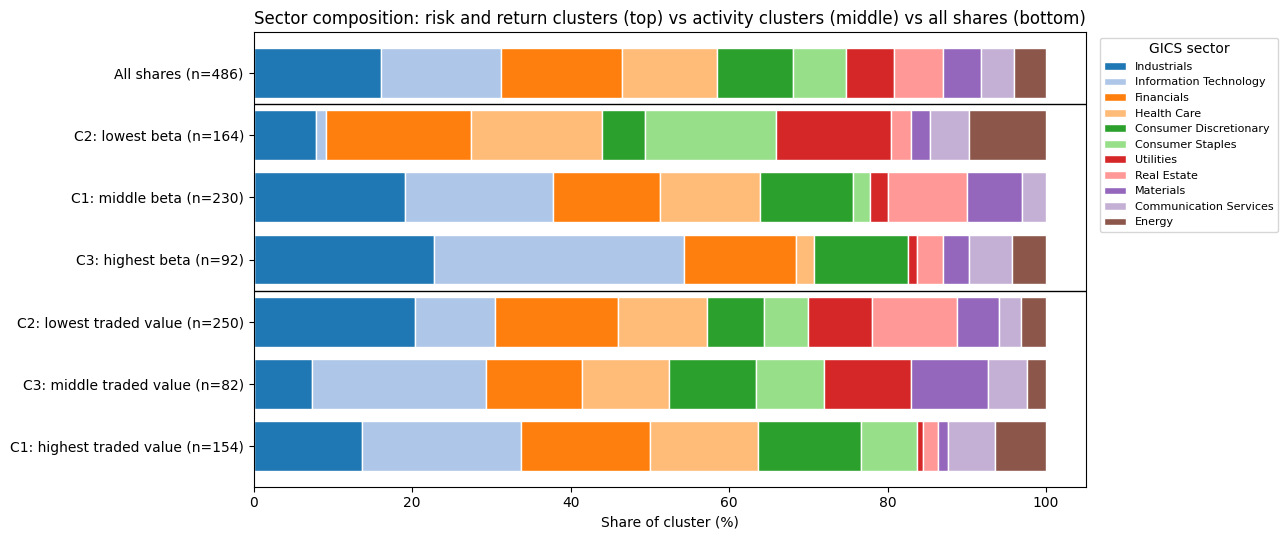

In [153]:
sector_order = features["GICS Sector"].value_counts().index.tolist()
sector_colours = [sns.color_palette("tab20", len(sector_order))[i] for i in range(len(sector_order))]
overall = features["GICS Sector"].value_counts(normalize=True).reindex(sector_order)
comp_rr = pd.crosstab(features["RR_Label"], features["GICS Sector"], normalize="index").reindex(index=rr_order, columns=sector_order)
comp_rfm = pd.crosstab(features["RFM_Label"], features["GICS Sector"], normalize="index").reindex(index=rfm_order, columns=sector_order)

n_lookup = {**rr_profile["N_Shares"].to_dict(), **rfm_profile["N_Shares"].to_dict()}
comp_all = pd.concat([overall.to_frame(f"All shares (n={len(features)})").T, comp_rr, comp_rfm])
comp_all.index = [i if i.startswith("All") else f"{i} (n={n_lookup[i]})" for i in comp_all.index]

fig, ax = plt.subplots(figsize=(13, 5.5))
comp_all.iloc[::-1].mul(100).plot(kind="barh", stacked=True, color=sector_colours, ax=ax, width=0.8, edgecolor="white")
ax.axhline(len(rfm_order) - 0.5, color="black", lw=1)
ax.axhline(len(rfm_order) + len(rr_order) - 0.5, color="black", lw=1)
ax.set_xlabel("Share of cluster (%)"); ax.set_title("Sector composition: risk and return clusters (top) vs activity clusters (middle) vs all shares (bottom)")
ax.legend(title="GICS sector", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
save_fig("g13_sector_composition")
plt.show()

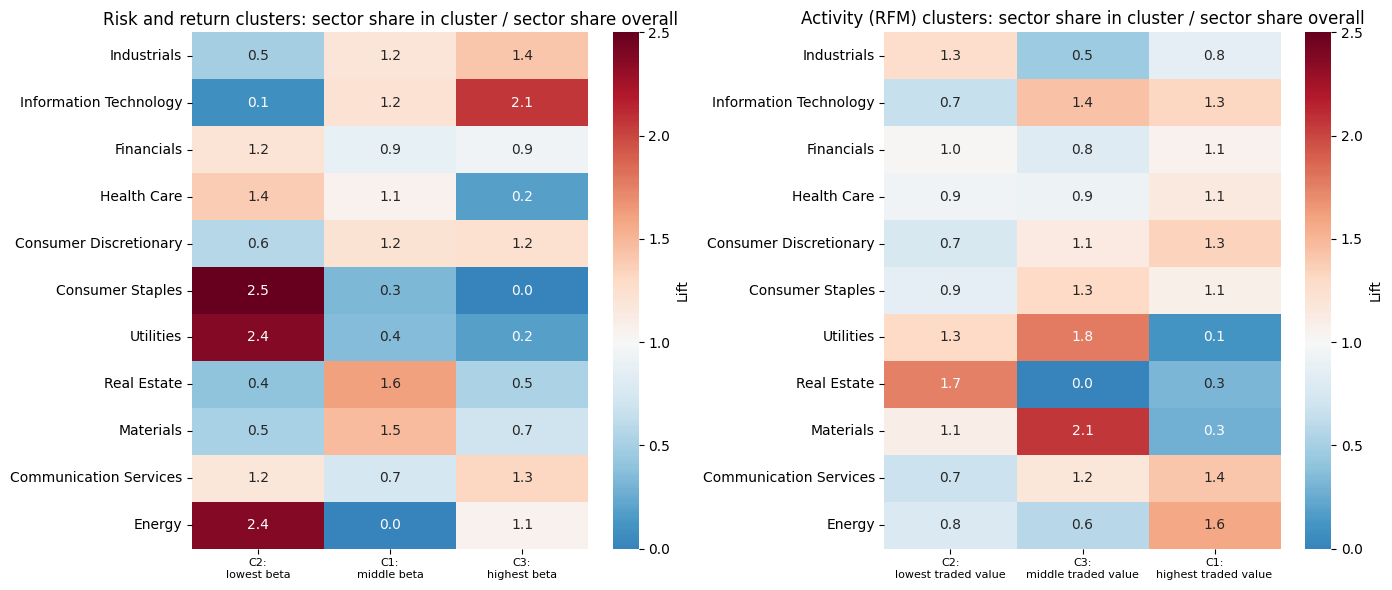

Lift above 1 = sector over-represented in the cluster. Small sectors give unstable lift values.


In [154]:
lift_rr = comp_rr.div(overall, axis=1)
lift_rfm = comp_rfm.div(overall, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, lift, title in [(axes[0], lift_rr, "Risk and return clusters"), (axes[1], lift_rfm, "Activity (RFM) clusters")]:
    sns.heatmap(lift.T, annot=True, fmt=".1f", cmap="RdBu_r", center=1, vmin=0, vmax=2.5, cbar_kws={"label": "Lift"}, ax=ax)
    ax.set_title(f"{title}: sector share in cluster / sector share overall")
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_xticklabels([t.get_text().replace(": ", ":\n") for t in ax.get_xticklabels()], rotation=0, fontsize=8)
plt.tight_layout()
save_fig("g14_sector_lift")
plt.show()
print("Lift above 1 = sector over-represented in the cluster. Small sectors give unstable lift values.")


ARI risk-return vs RFM: 0.024 | chi-square p = 0.0221 | Cramer's V = 0.108
Cells with expected count below 5: 0 of 9


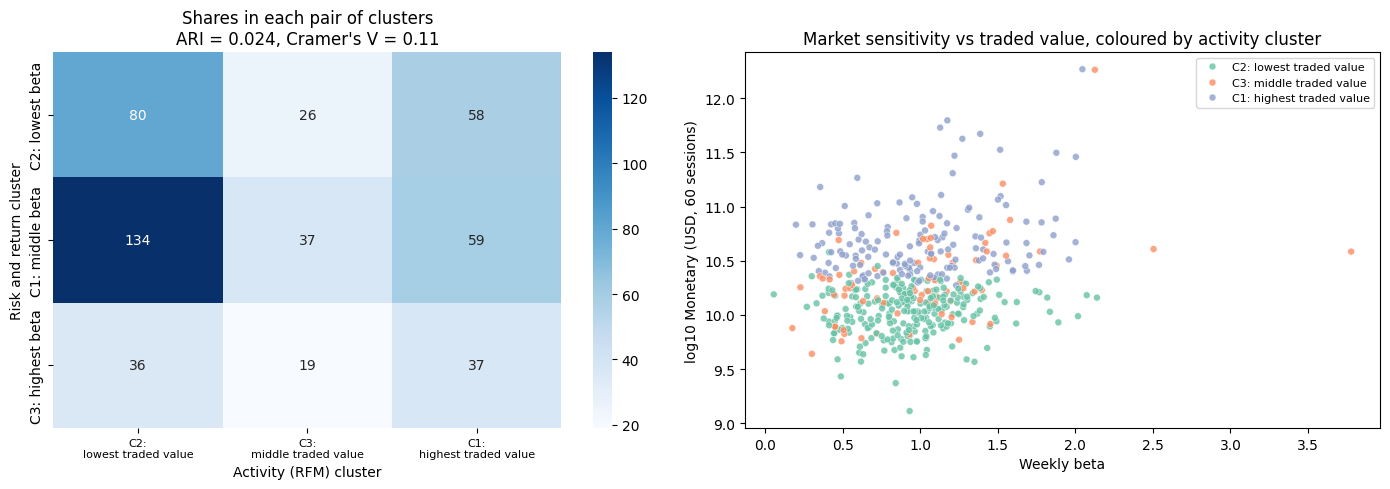

In [155]:
ct = pd.crosstab(features["RR_Label"], features["RFM_Label"]).reindex(index=rr_order, columns=rfm_order)
chi2, p_chi, dof, expected = chi2_contingency(ct)
cramer_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
ari_cross = adjusted_rand_score(features["Ward_RR"], features["Ward_RFM"])
print(f"ARI risk-return vs RFM: {ari_cross:.3f} | chi-square p = {p_chi:.4f} | Cramer's V = {cramer_v:.3f}")
print("Cells with expected count below 5:", int((expected < 5).sum()), "of", expected.size)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title(f"Shares in each pair of clusters\nARI = {ari_cross:.3f}, Cramer's V = {cramer_v:.2f}")
axes[0].set_xlabel("Activity (RFM) cluster"); axes[0].set_ylabel("Risk and return cluster")
axes[0].set_xticklabels([t.get_text().replace(": ", ":\n") for t in axes[0].get_xticklabels()], rotation=0, fontsize=8)
sns.scatterplot(data=features, x="Weekly_Beta", y="log10_M", hue="RFM_Label", hue_order=rfm_order, palette="Set2", s=25, alpha=0.8, ax=axes[1])
axes[1].set_xlabel("Weekly beta"); axes[1].set_ylabel("log10 Monetary (USD, 60 sessions)")
axes[1].set_title("Market sensitivity vs traded value, coloured by activity cluster")
axes[1].legend(fontsize=8)
plt.tight_layout()
save_fig("g15_rr_vs_rfm_agreement")
plt.show()

Sensitivity findings and Business Uses

In [156]:
corr_p = X_rfm_raw.corr()
corr_s = X_rfm_raw.corr(method="spearman")

pca_full = PCA(n_components=3, random_state=random_seed).fit(X_rfm)
print("PCA explained variance ratio (R, F, log1p M):", pca_full.explained_variance_ratio_.round(3))
print(pd.DataFrame(pca_full.components_.T, index=X_rfm.columns, columns=["PC1", "PC2", "PC3"]).round(3))

d_full = pdist(X_rfm.values)
X_rf_std = StandardScaler().fit_transform(features[["R", "F"]])
dist_sets = {"R only": pdist(X_rfm[["R"]].values), "F only": pdist(X_rfm[["F"]].values), "log1p(M) only": pdist(X_rfm[["log1p_M"]].values),
             "R and F (re-standardised)": pdist(X_rf_std)}
dist_table = pd.DataFrame({"Feature_set": list(dist_sets), "Corr_with_full_RFM_distance": [np.corrcoef(d, d_full)[0, 1] for d in dist_sets.values()]})
print()
print(dist_table.round(3).to_string(index=False))

PCA explained variance ratio (R, F, log1p M): [0.458 0.336 0.206]
           PC1    PC2    PC3
R        0.711  0.023  0.703
F       -0.650  0.402  0.645
log1p_M  0.268  0.915 -0.301

              Feature_set  Corr_with_full_RFM_distance
                   R only                        0.701
                   F only                        0.608
            log1p(M) only                        0.580
R and F (re-standardised)                        0.857


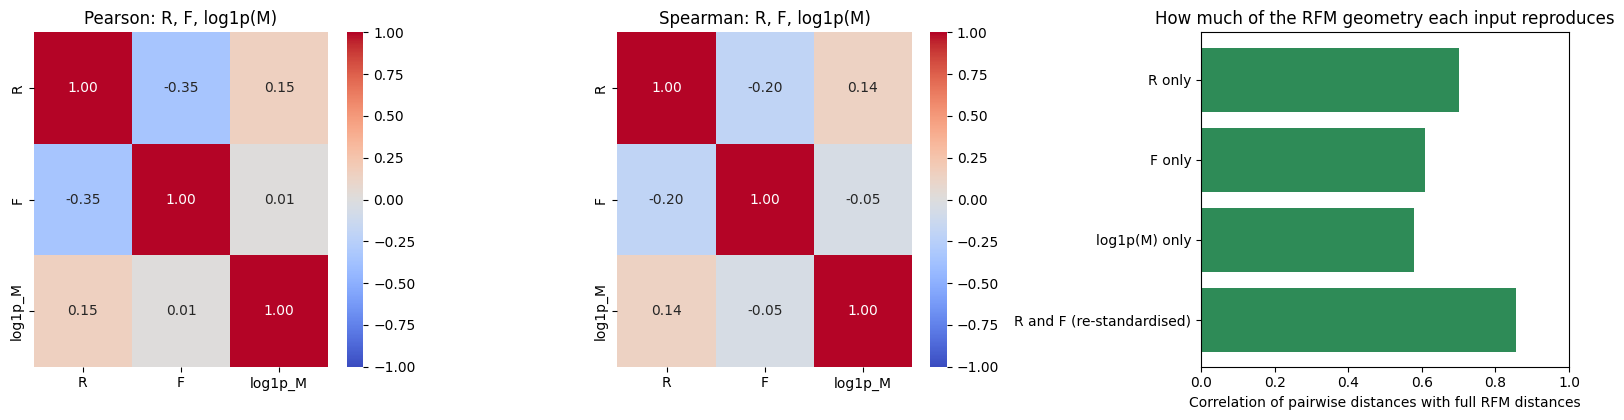

In [157]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
sns.heatmap(corr_p, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0]); axes[0].set_title("Pearson: R, F, log1p(M)")
sns.heatmap(corr_s, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1]); axes[1].set_title("Spearman: R, F, log1p(M)")
axes[2].barh(dist_table["Feature_set"][::-1], dist_table["Corr_with_full_RFM_distance"][::-1], color="seagreen")
axes[2].set_xlim(0, 1); axes[2].set_xlabel("Correlation of pairwise distances with full RFM distances")
axes[2].set_title("How much of the RFM geometry each input reproduces")
plt.tight_layout()
save_fig("g16_rfm_overlap_and_distances")
plt.show()

In [158]:
def eta_squared(values, groups):
    values, groups = np.asarray(values, dtype=float), np.asarray(groups)
    ss_total = ((values - values.mean()) ** 2).sum()
    ss_between = sum((groups == g).sum() * (values[groups == g].mean() - values.mean()) ** 2 for g in np.unique(groups))
    return ss_between / ss_total

ari_rf = adjusted_rand_score(features["Ward_RFM"], features["Ward_RF_only"])
eta_table = pd.DataFrame({
    "Feature": ["R", "F", "log10 M"],
    "Eta2_Ward_RFM": [eta_squared(features[c], features["Ward_RFM"]) for c in ["R", "F", "log10_M"]],
    "Eta2_Ward_RF_only": [eta_squared(features[c], features["Ward_RF_only"]) for c in ["R", "F", "log10_M"]]})
print(f"ARI Ward RFM vs Ward R,F only (k = {k_ward_rfm}): {ari_rf:.3f}")
print("Share of each feature's variance explained by cluster membership (eta squared):")
print(eta_table.round(3).to_string(index=False))

ARI Ward RFM vs Ward R,F only (k = 3): 0.291
Share of each feature's variance explained by cluster membership (eta squared):
Feature  Eta2_Ward_RFM  Eta2_Ward_RF_only
      R          0.642              0.646
      F          0.119              0.543
log10 M          0.516              0.004


In [159]:
rf_rank = features.groupby("Ward_RF_only")["M"].median().sort_values().index.tolist()
rf_names = {c: f"RF-{i + 1}" for i, c in enumerate(rf_rank)}
features["RF_Label"] = features["Ward_RF_only"].map(rf_names)
rf_order = [rf_names[c] for c in rf_rank]
print("\nTraded value M (USD billions) by R,F-only cluster")
print(features.groupby("RF_Label")["M_Billion"].agg(["count", "median", "mean"]).reindex(rf_order).round(2))


Traded value M (USD billions) by R,F-only cluster
          count  median   mean
RF_Label                      
RF-1        272   14.86  39.40
RF-2        125   17.70  34.34
RF-3         89   20.85  46.53


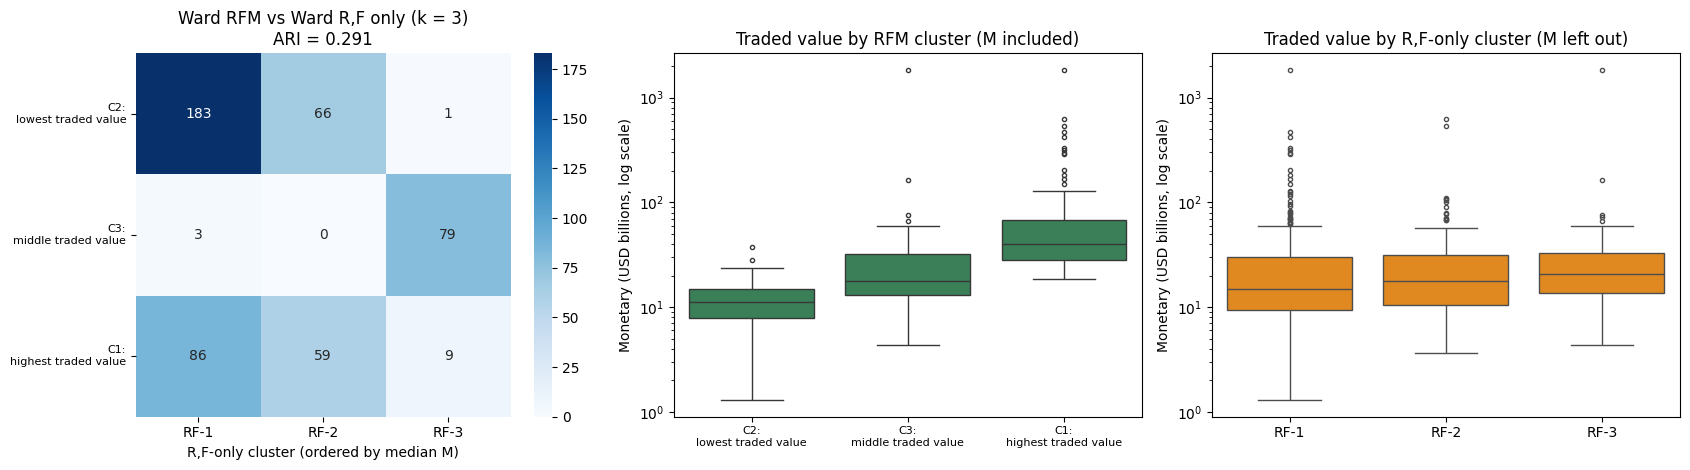

In [160]:
ct_rf = pd.crosstab(features["RFM_Label"], features["RF_Label"]).reindex(index=rfm_order, columns=rf_order)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.heatmap(ct_rf, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title(f"Ward RFM vs Ward R,F only (k = {k_ward_rfm})\nARI = {ari_rf:.3f}")
axes[0].set_xlabel("R,F-only cluster (ordered by median M)"); axes[0].set_ylabel("")
axes[0].set_yticklabels([t.get_text().replace(": ", ":\n") for t in axes[0].get_yticklabels()], rotation=0, fontsize=8)
sns.boxplot(data=features, x="RFM_Label", y="M_Billion", order=rfm_order, color="seagreen", fliersize=3, ax=axes[1])
axes[1].set_yscale("log"); axes[1].set_xlabel(""); axes[1].set_ylabel("Monetary (USD billions, log scale)")
axes[1].set_title("Traded value by RFM cluster (M included)")
axes[1].set_xticks(range(len(rfm_order))); axes[1].set_xticklabels([o.replace(": ", ":\n") for o in rfm_order], fontsize=8)
sns.boxplot(data=features, x="RF_Label", y="M_Billion", order=rf_order, color="darkorange", fliersize=3, ax=axes[2])
axes[2].set_yscale("log"); axes[2].set_xlabel(""); axes[2].set_ylabel("Monetary (USD billions, log scale)")
axes[2].set_title("Traded value by R,F-only cluster (M left out)")
plt.tight_layout()
save_fig("g17_monetary_removal")
plt.show()

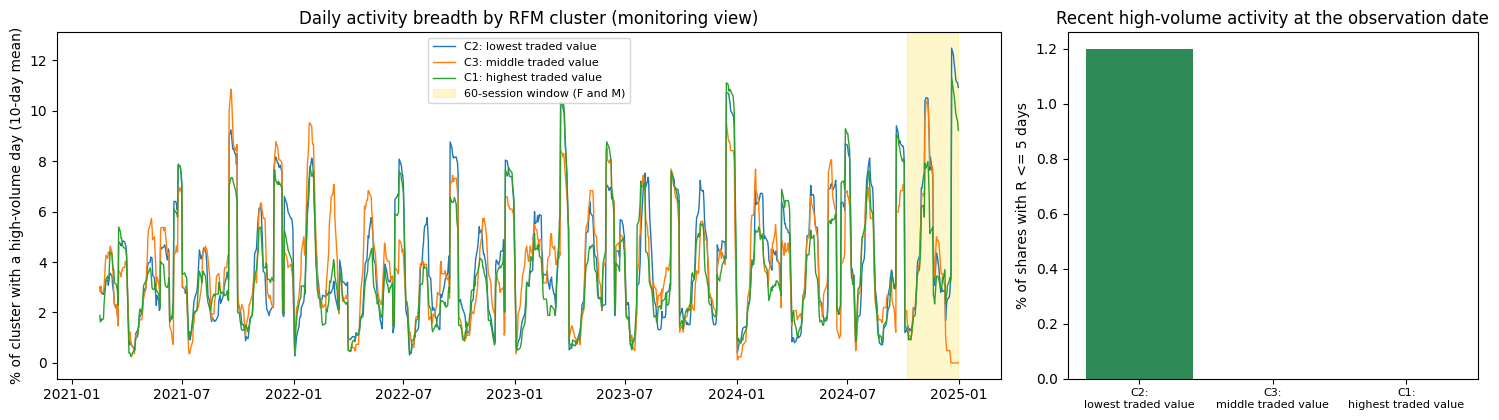

Activity watchlist (most frequent, then most recent high-volume days) - an attention list, not a trading signal


,Ticker,Security,GICS Sector,R,F,M_Billion,RFM_Label
103,CI,Cigna,Health Care,13,8,37.90,C2: lowest traded value
221,HSY,Hershey Company (The),Consumer Staples,20,8,22.74,C2: lowest traded value
197,FOXA,Fox Corporation (Class A),Communication Services,11,7,9.39,C2: lowest traded value
480,XEL,Xcel Energy,Utilities,11,7,15.04,C2: lowest traded value
446,UNH,UnitedHealth Group,Health Care,14,7,151.31,C1: highest traded value
45,AJG,Arthur J. Gallagher & Co.,Financials,4,6,28.24,C2: lowest traded value
23,AMCR,Amcor,Materials,11,6,7.69,C2: lowest traded value
72,AVGO,Broadcom,Information Technology,11,6,334.04,C1: highest traded value
105,CTAS,Cintas,Industrials,11,6,20.42,C2: lowest traded value
251,IQV,IQVIA,Health Care,11,6,19.38,C2: lowest traded value


In [161]:
cl_map = features["RFM_Label"].values
breadth_cl = (flags_all[tk].T.groupby(cl_map).mean().T * 100).iloc[20:][rfm_order].rolling(10).mean()
recent_share = (features["R"] <= 5).groupby(features["RFM_Label"]).mean().reindex(rfm_order) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3), gridspec_kw={"width_ratios": [2.3, 1]})
for c in rfm_order:
    axes[0].plot(breadth_cl.index, breadth_cl[c], lw=1, label=c)
axes[0].axvspan(last60_dates[0], last60_dates[-1], color="gold", alpha=0.2, label="60-session window (F and M)")
axes[0].set_ylabel("% of cluster with a high-volume day (10-day mean)")
axes[0].set_title("Daily activity breadth by RFM cluster (monitoring view)")
axes[0].legend(fontsize=8)
axes[1].bar([o.replace(": ", ":\n") for o in rfm_order], recent_share.values, color="seagreen")
axes[1].set_ylabel("% of shares with R <= 5 days"); axes[1].set_title("Recent high-volume activity at the observation date")
axes[1].tick_params(axis="x", labelsize=8)
plt.tight_layout()
save_fig("g18_activity_monitoring")
plt.show()

watchlist = features.sort_values(["F", "R"], ascending=[False, True]).head(10)[["Ticker", "Security", "GICS Sector", "R", "F", "M_Billion", "RFM_Label"]]
print("Activity watchlist (most frequent, then most recent high-volume days) - an attention list, not a trading signal")
display(watchlist.round(2))
watchlist.to_csv("outputs/task3_activity_watchlist.csv", index=False)

Critical Evaluation and Limitations

Mean pairwise weekly-return correlation across all 486 shares: 0.300


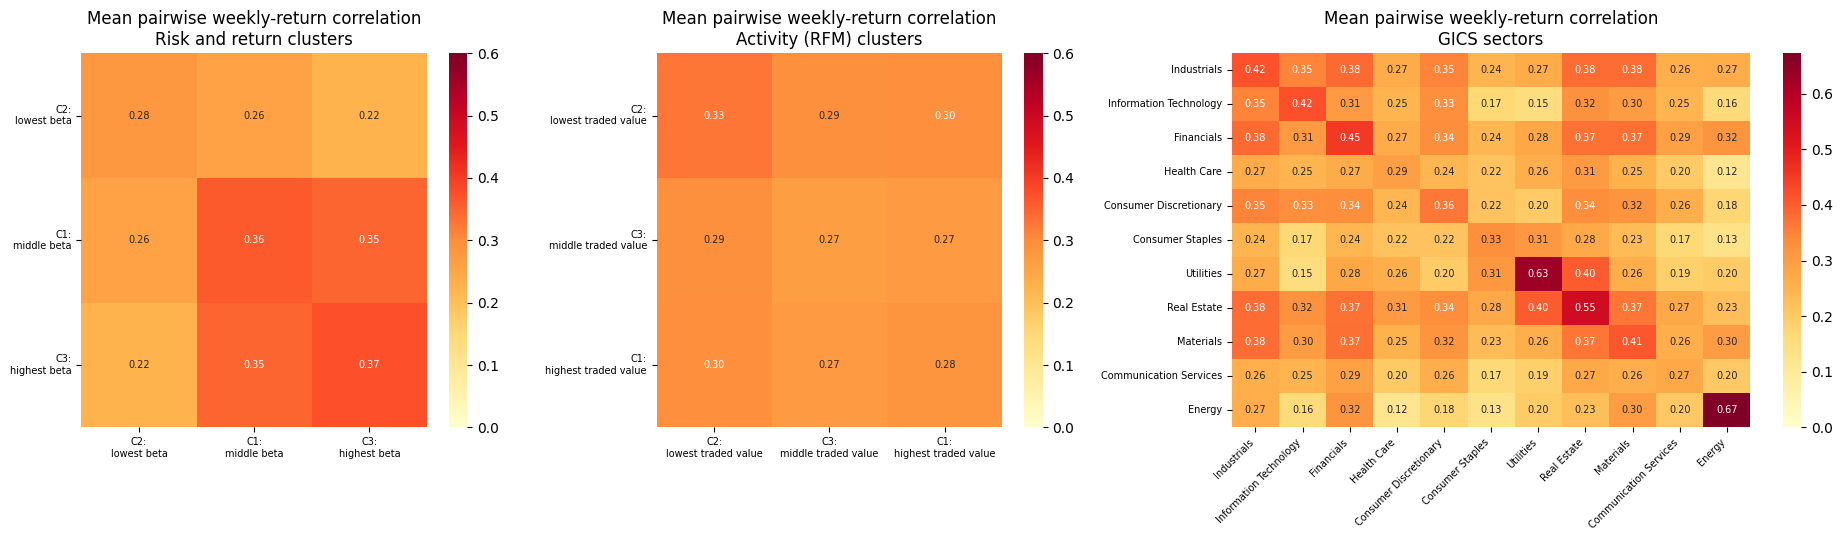

In [162]:
ret = weekly_returns[tk]
corr_ret = ret.corr().values

def block_corr(labels):
    labs = np.asarray(labels)
    groups = [g for g in pd.unique(labs)]
    out = pd.DataFrame(index=groups, columns=groups, dtype=float)
    for a in groups:
        ia = np.where(labs == a)[0]
        for b in groups:
            ib = np.where(labs == b)[0]
            sub = corr_ret[np.ix_(ia, ib)]
            if a == b:
                vals = sub[~np.eye(len(ia), dtype=bool)] if len(ia) > 1 else np.array([np.nan])
            else:
                vals = sub.ravel()
            out.loc[a, b] = np.nanmean(vals)
    return out


bc_rr = block_corr(features["RR_Label"]).reindex(index=rr_order, columns=rr_order)
bc_rfm = block_corr(features["RFM_Label"]).reindex(index=rfm_order, columns=rfm_order)
bc_sec = block_corr(features["GICS Sector"]).reindex(index=sector_order, columns=sector_order)
off_diag = corr_ret[~np.eye(len(tk), dtype=bool)]
print(f"Mean pairwise weekly-return correlation across all {len(tk)} shares: {off_diag.mean():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), gridspec_kw={"width_ratios": [1, 1, 1.5]})
for ax, bc, title in [(axes[0], bc_rr, "Risk and return clusters"), (axes[1], bc_rfm, "Activity (RFM) clusters"), (axes[2], bc_sec, "GICS sectors")]:
    sns.heatmap(bc, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=max(0.6, np.nanmax(bc.values)), ax=ax, annot_kws={"fontsize": 7})
    ax.set_title(f"Mean pairwise weekly-return correlation\n{title}")
    ax.set_xticklabels([t.get_text().replace(": ", ":\n") for t in ax.get_xticklabels()], rotation=45 if ax is axes[2] else 0, ha="right" if ax is axes[2] else "center", fontsize=7)
    ax.set_yticklabels([t.get_text().replace(": ", ":\n") for t in ax.get_yticklabels()], rotation=0, fontsize=7)
plt.tight_layout()
save_fig("g19_return_dependencies")
plt.show()

Median difference in mean weekly return (Adj - Close): 2.93 bps | maximum: 15.16 bps
Spearman correlation of beta (Adj vs Close): 0.9999 | shares with |beta difference| > 0.01: 24


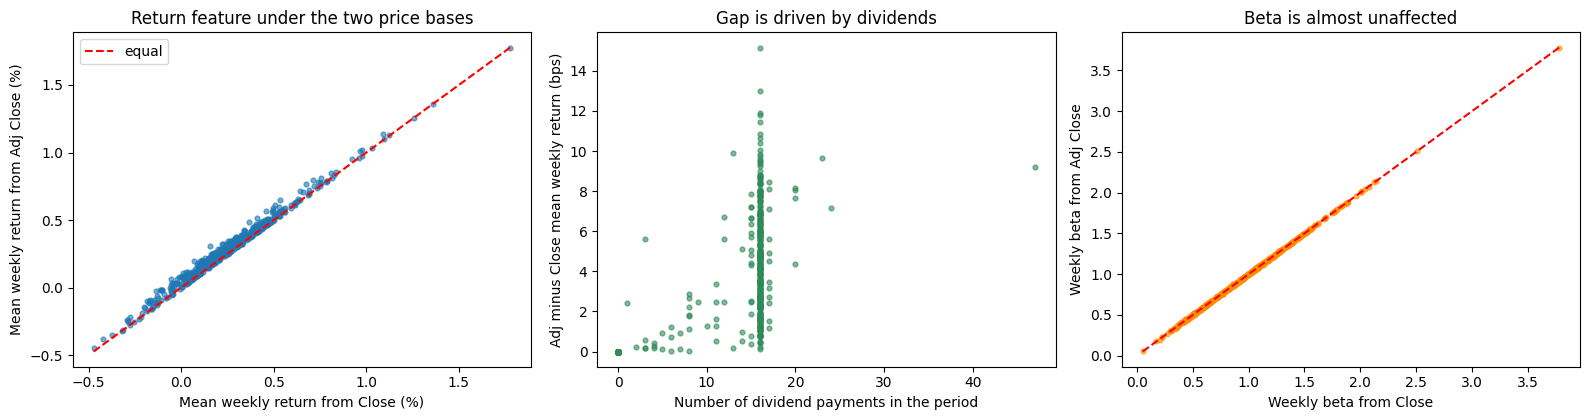

In [163]:
weekly_close = close_v.resample("W-FRI").last().iloc[:-1]
close_returns = calculate_weekly_returns(weekly_close)
bench_close_returns = calculate_weekly_returns(bench["Close"].resample("W-FRI").last().iloc[:-1])

adj_cmp = pd.DataFrame({"Ticker": tk.values,
                        "Mean_Return_Adj": weekly_returns[tk].mean().values,
                        "Mean_Return_Close": close_returns[tk].mean().values,
                        "Beta_Adj": features["Weekly_Beta"].values,
                        "Beta_Close": [calculate_weekly_beta(close_returns[t], bench_close_returns)[0] for t in tk]})
adj_cmp["Return_Diff_bps"] = (adj_cmp["Mean_Return_Adj"] - adj_cmp["Mean_Return_Close"]) * 1e4
adj_cmp["Dividend_Days"] = corp.loc[tk, "Dividends"].values
beta_rho = spearmanr(adj_cmp["Beta_Adj"], adj_cmp["Beta_Close"])[0]
print(f"Median difference in mean weekly return (Adj - Close): {adj_cmp['Return_Diff_bps'].median():.2f} bps | maximum: {adj_cmp['Return_Diff_bps'].max():.2f} bps")
print(f"Spearman correlation of beta (Adj vs Close): {beta_rho:.4f} | shares with |beta difference| > 0.01: {(adj_cmp['Beta_Adj'] - adj_cmp['Beta_Close']).abs().gt(0.01).sum()}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].scatter(adj_cmp["Mean_Return_Close"] * 100, adj_cmp["Mean_Return_Adj"] * 100, s=12, alpha=0.6)
lims = [adj_cmp[["Mean_Return_Close", "Mean_Return_Adj"]].min().min() * 100, adj_cmp[["Mean_Return_Close", "Mean_Return_Adj"]].max().max() * 100]
axes[0].plot(lims, lims, color="red", ls="--", label="equal")
axes[0].set_xlabel("Mean weekly return from Close (%)"); axes[0].set_ylabel("Mean weekly return from Adj Close (%)"); axes[0].legend()
axes[0].set_title("Return feature under the two price bases")
axes[1].scatter(adj_cmp["Dividend_Days"], adj_cmp["Return_Diff_bps"], s=12, alpha=0.6, color="seagreen")
axes[1].set_xlabel("Number of dividend payments in the period"); axes[1].set_ylabel("Adj minus Close mean weekly return (bps)")
axes[1].set_title("Gap is driven by dividends")
axes[2].scatter(adj_cmp["Beta_Close"], adj_cmp["Beta_Adj"], s=12, alpha=0.6, color="darkorange")
axes[2].plot([adj_cmp["Beta_Close"].min(), adj_cmp["Beta_Close"].max()], [adj_cmp["Beta_Close"].min(), adj_cmp["Beta_Close"].max()], color="red", ls="--")
axes[2].set_xlabel("Weekly beta from Close"); axes[2].set_ylabel("Weekly beta from Adj Close"); axes[2].set_title("Beta is almost unaffected")
plt.tight_layout()
save_fig("g20_price_adjustment_check")
plt.show()

Clustered shares that joined the index on/after 2021-01-01: 72 of 486 (14.8%)
                                            count    mean  median
Index_Entry                                                      
Added during/after study period                72  0.4669  0.4453
In index before study (or date not stated)    414  0.2542  0.2542
Mann-Whitney U p-value (mean weekly return, added vs earlier): 0.0000


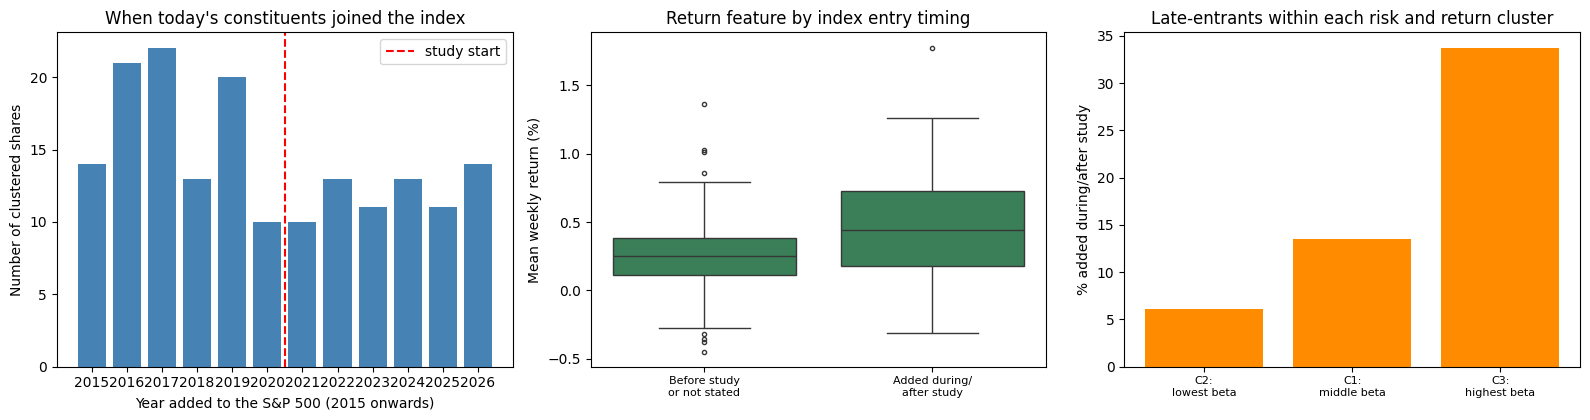

In [164]:
if "Date added" in sp500.columns:
    added_map = pd.Series(pd.to_datetime(sp500["Date added"], errors="coerce").values, index=sp500["Symbol"])
    added_map = added_map[~added_map.index.duplicated()]
    features["Date_Added"] = features["Ticker"].map(added_map)
    features["Index_Entry"] = np.where(features["Date_Added"] >= pd.Timestamp(start_date), "Added during/after study period", "In index before study (or date not stated)")
    n_after = int((features["Index_Entry"] == "Added during/after study period").sum())
    print(f"Clustered shares that joined the index on/after {start_date}: {n_after} of {len(features)} ({n_after / len(features):.1%})")
    grp = features.groupby("Index_Entry")["Return_pct"].agg(["count", "mean", "median"]).round(4)
    print(grp)
    if n_after >= 5:
        u = mannwhitneyu(features.loc[features["Index_Entry"].str.startswith("Added"), "Return_pct"],
                         features.loc[~features["Index_Entry"].str.startswith("Added"), "Return_pct"])
        print(f"Mann-Whitney U p-value (mean weekly return, added vs earlier): {u.pvalue:.4f}")

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
    yrs = features["Date_Added"].dt.year.fillna(0).astype(int).replace(0, np.nan)
    yr_counts = yrs[yrs >= 2015].value_counts().sort_index() if yrs.notna().any() else pd.Series(dtype=int)
    axes[0].bar(yr_counts.index.astype(int).astype(str), yr_counts.values, color="steelblue")
    axes[0].axvline(x=list(yr_counts.index).index(2021) - 0.5 if 2021 in yr_counts.index else 0, color="red", ls="--", label="study start")
    axes[0].set_xlabel("Year added to the S&P 500 (2015 onwards)"); axes[0].set_ylabel("Number of clustered shares"); axes[0].legend()
    axes[0].set_title("When today's constituents joined the index")
    sns.boxplot(data=features, x="Index_Entry", y="Return_pct", color="seagreen", fliersize=3, ax=axes[1])
    axes[1].set_xticks(range(2)); axes[1].set_xticklabels(["Before study\nor not stated" if "before" in t.get_text() else "Added during/\nafter study" for t in axes[1].get_xticklabels()], fontsize=8)
    axes[1].set_xlabel(""); axes[1].set_ylabel("Mean weekly return (%)"); axes[1].set_title("Return feature by index entry timing")
    share_added = (features["Index_Entry"] == "Added during/after study period").groupby(features["RR_Label"]).mean().reindex(rr_order) * 100
    axes[2].bar([o.replace(": ", ":\n") for o in rr_order], share_added.values, color="darkorange")
    axes[2].set_ylabel("% added during/after study"); axes[2].set_title("Late-entrants within each risk and return cluster")
    axes[2].tick_params(axis="x", labelsize=8)
    plt.tight_layout()
    save_fig("g21_survivorship_check")
    plt.show()
else:
    print("'Date added' column not available in the ticker table - survivorship check skipped.")

In [165]:
vol60 = volume_v.loc[last60_dates, tk].mean().values
px60 = close_v.loc[last60_dates, tk].mean().values
liq = pd.DataFrame({"Sector": features["GICS Sector"].values, "M_Billion": features["M_Billion"].values, "Mean_Volume_M": vol60 / 1e6, "Mean_Close": px60})
rho_mv = spearmanr(liq["M_Billion"], liq["Mean_Volume_M"])[0]
print(f"Spearman correlation: Monetary vs average share volume = {rho_mv:.3f}")

Spearman correlation: Monetary vs average share volume = 0.564


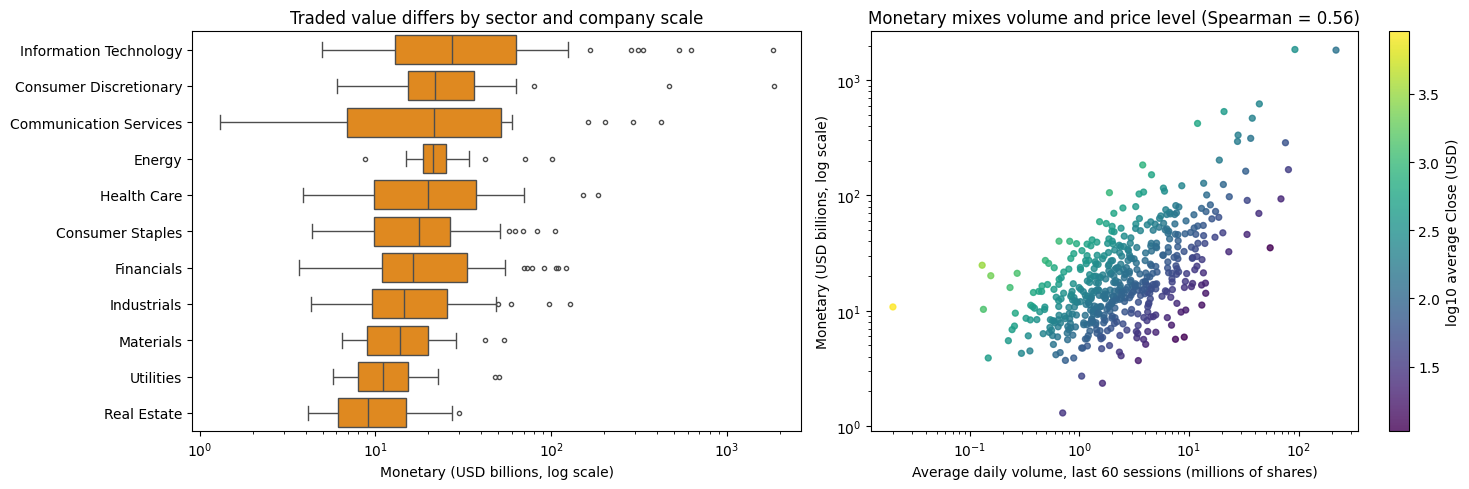

In [166]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sec_order = liq.groupby("Sector")["M_Billion"].median().sort_values(ascending=False).index
sns.boxplot(data=liq, y="Sector", x="M_Billion", order=sec_order, color="darkorange", fliersize=3, ax=axes[0])
axes[0].set_xscale("log"); axes[0].set_xlabel("Monetary (USD billions, log scale)"); axes[0].set_ylabel("")
axes[0].set_title("Traded value differs by sector and company scale")
sc = axes[1].scatter(liq["Mean_Volume_M"], liq["M_Billion"], c=np.log10(liq["Mean_Close"]), cmap="viridis", s=18, alpha=0.8)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("Average daily volume, last 60 sessions (millions of shares)"); axes[1].set_ylabel("Monetary (USD billions, log scale)")
axes[1].set_title(f"Monetary mixes volume and price level (Spearman = {rho_mv:.2f})")
plt.colorbar(sc, ax=axes[1], label="log10 average Close (USD)")
plt.tight_layout()
save_fig("g22_liquidity_proxy_limits")
plt.show()

In [167]:
mid = len(weekly_returns) // 2
h1, h2 = weekly_returns.iloc[:mid], weekly_returns.iloc[mid:]
b1, b2 = bench_returns.iloc[:mid], bench_returns.iloc[mid:]
print("First half:", h1.index[0].date(), "to", h1.index[-1].date(), "| second half:", h2.index[0].date(), "to", h2.index[-1].date())

First half: 2021-01-15 to 2022-12-30 | second half: 2023-01-06 to 2024-12-27


In [168]:
persist = pd.DataFrame({"Ticker": tk.values})
persist["Return_H1"] = h1[tk].mean().values * 100
persist["Return_H2"] = h2[tk].mean().values * 100
persist["Beta_H1"] = (h1[tk].apply(lambda s: s.cov(b1)) / b1.var()).values
persist["Beta_H2"] = (h2[tk].apply(lambda s: s.cov(b2)) / b2.var()).values

prior_dates = volume_v.index[-120:-60]
prior_end = prior_dates[-1]
persist["F_prior"] = flags_all.loc[prior_dates, tk].sum().values
persist["M_prior"] = (close_v.loc[prior_dates, tk] * volume_v.loc[prior_dates, tk]).sum().values
last_ev = flags_all.loc[:prior_end, tk].apply(lambda s: s.index[s.values][-1] if s.values.any() else pd.NaT)
persist["R_prior"] = (prior_end - last_ev).dt.days.values
persist["R"], persist["F"], persist["M"] = features["R"].values, features["F"].values, features["M"].values
persist["Beta_full"] = features["Weekly_Beta"].values
persist["RR_Label"] = features["RR_Label"].values

pairs = [("Mean weekly return", "Return_H1", "Return_H2"), ("Weekly beta", "Beta_H1", "Beta_H2"),
         ("Recency (R)", "R_prior", "R"), ("Frequency (F)", "F_prior", "F"), ("Monetary (M)", "M_prior", "M")]
rho_rows = []
for name, a, b in pairs:
    rho, p = spearmanr(persist[a], persist[b], nan_policy="omit")
    rho_rows.append([name, rho, p])
persist_table = pd.DataFrame(rho_rows, columns=["Feature", "Spearman_rho", "p_value"])
print(persist_table.round(4).to_string(index=False))

           Feature  Spearman_rho  p_value
Mean weekly return       -0.1441   0.0015
       Weekly beta        0.7956   0.0000
       Recency (R)        0.1355   0.0028
     Frequency (F)        0.0245   0.5899
      Monetary (M)        0.9679   0.0000


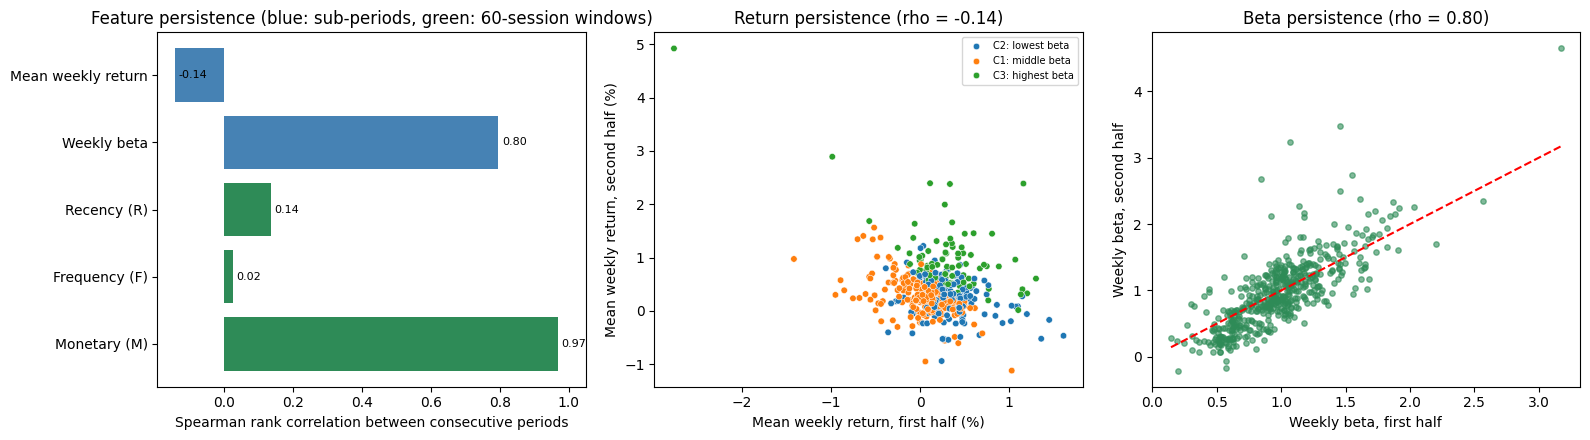

In [169]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
colours = ["steelblue" if f in ("Mean weekly return", "Weekly beta") else "seagreen" for f in persist_table["Feature"]]
axes[0].barh(persist_table["Feature"][::-1], persist_table["Spearman_rho"][::-1], color=colours[::-1])
for i, v in enumerate(persist_table["Spearman_rho"][::-1]):
    axes[0].text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8)
axes[0].set_xlim(min(-0.1, persist_table["Spearman_rho"].min() - 0.05), 1.05)
axes[0].set_xlabel("Spearman rank correlation between consecutive periods")
axes[0].set_title("Feature persistence (blue: sub-periods, green: 60-session windows)")
sns.scatterplot(data=persist, x="Return_H1", y="Return_H2", hue="RR_Label", hue_order=rr_order, palette="tab10", s=22, ax=axes[1])
axes[1].set_xlabel("Mean weekly return, first half (%)"); axes[1].set_ylabel("Mean weekly return, second half (%)")
axes[1].set_title(f"Return persistence (rho = {persist_table.loc[0, 'Spearman_rho']:.2f})"); axes[1].legend(fontsize=7)
axes[2].scatter(persist["Beta_H1"], persist["Beta_H2"], s=15, alpha=0.6, color="seagreen")
axes[2].plot([persist["Beta_H1"].min(), persist["Beta_H1"].max()], [persist["Beta_H1"].min(), persist["Beta_H1"].max()], color="red", ls="--")
axes[2].set_xlabel("Weekly beta, first half"); axes[2].set_ylabel("Weekly beta, second half")
axes[2].set_title(f"Beta persistence (rho = {persist_table.loc[1, 'Spearman_rho']:.2f})")
plt.tight_layout()
save_fig("g23_feature_persistence")
plt.show()

In [170]:
rr_profile.to_csv("outputs/task3_rr_cluster_profile.csv")
rfm_profile.to_csv("outputs/task3_rfm_cluster_profile.csv")
comp_all.to_csv("outputs/task3_sector_composition.csv")
dist_table.to_csv("outputs/task3_distance_overlap.csv", index=False)
eta_table.to_csv("outputs/task3_eta_squared.csv", index=False)
persist_table.to_csv("outputs/task3_feature_persistence.csv", index=False)
adj_cmp.to_csv("outputs/task3_adjclose_vs_close.csv", index=False)
features.to_csv("outputs/feature_table_with_clusters_and_labels.csv", index=False)
print(sorted(os.listdir("outputs")))

['exclusion_log.csv', 'feature_table.csv', 'feature_table_with_clusters.csv', 'feature_table_with_clusters_and_labels.csv', 'fig_choose_k.png', 'fig_cluster_scatter.png', 'fig_dendrogram_rfm.png', 'fig_dendrogram_risk_return.png', 'fig_distributions.png', 'fig_rfm_correlation.png', 'fig_standardised_profiles.png', 'g10_choose_k.png', 'g11_data_mart_star_schema.png', 'g12_cluster_profiles_original_units.png', 'g13_sector_composition.png', 'g14_sector_lift.png', 'g15_rr_vs_rfm_agreement.png', 'g16_rfm_overlap_and_distances.png', 'g17_monetary_removal.png', 'g18_activity_monitoring.png', 'g19_return_dependencies.png', 'g1_attrition_funnel.png', 'g20_price_adjustment_check.png', 'g21_survivorship_check.png', 'g22_liquidity_proxy_limits.png', 'g23_feature_persistence.png', 'g2_exclusion_timeline.png', 'g3_return_beta_distributions.png', 'g4_beta_examples.png', 'g6_market_wide_breadth.png', 'g7_worked_example.png', 'g8_feature_distributions.png', 'g9_standardised_boxplots.png', 'g_rfm_only_d